In [1]:
from IPython.display import HTML

styles = open('library/markdown_style.css').read()
HTML(styles)

# Bike Share Ridership in California
**Author:** Andres Sanchez<br/>
**Data:** 60 months from July 2021 thru June 2026<br/>
**GitHub:** `git@github.com:andrsanc/Bike-Ridership-in-California.git`<br/>

*Benchmark run locally on an Apple Silicon Mac*

# Executive Summary
### How do Californians ride, and how does that differ from one region to the next?
<a id="exec_summary"></a>

This project explores the biking habits of bike-share riders in Southern and Northern California, looking to uncover seasonal rhythms, regional differences, and the factors that drive ridership, using a full toolkit of classical and Bayesian statistical inference.

Public investment in cycling infrastructure has accelerated in recent years, and Los Angeles County offers a clear example. Since 2012, [LA County Public Works][1] has completed 41 projects to improve biking conditions, adding more than 75 miles of new construction, with many more projects planned or under way. These investments are part of a broader effort to reduce the region’s dependence on cars by creating better roads for cyclists and making riding safer for everyone.

Against this backdrop, the project examines how Californians use bike share programs and compares usage in Southern California with that in Northern California and across the state as a whole. By analyzing when, where, and for how long people ride, the analysis asks whether bike share serves different purposes in different regions, whether as a commuting tool, a connector to public transit, or a recreational activity. It also considers what those differences imply for where future investment in cycling infrastructure is likely to be most effective.

[1]: https://pw.lacounty.gov/tpp/bike/index.cfm?action=projects&CFID=73153822&CFTOKEN=6d74aa096542fc89-E8F5981C-BBE2-885E-EA394C55251D9130

In [2]:
use_raw_data = True

In [3]:
import warnings

# Silence bootstrap warnings when using sample data
if use_raw_data:
    data_prefix = 'data/raw/'
    data_type = 'Complete'
    part1_bs_n = 500
else:
    data_prefix = 'data/sample/'
    data_type = 'Sample'
    part1_bs_n = 20
    warnings.filterwarnings('ignore',
                            category = RuntimeWarning,
                            module = r'statsmodels\.discrete\.discrete_model')

print(data_prefix)

data/raw/


In [4]:
import math, os, requests, time, folium, io, random, re, html
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from folium.plugins import PolyLineTextPath
import statsmodels.formula.api as smf
import statsmodels.api as sm
import matplotlib.gridspec as gridspec
import matplotlib.pylab as pl
import scipy.stats as ss

# For MCMC
import pymc as pm
import arviz_plots as azp 
import arviz as az
import xarray as xr
import pytensor
from statsmodels.tools.sm_exceptions import ConvergenceWarning, HessianInversionWarning
warnings.simplefilter('ignore', ConvergenceWarning)
warnings.simplefilter('ignore', HessianInversionWarning)
np.seterr(over = 'ignore')
pytensor.config.cxx = "" # Apple Silicon Mac; prevents MCMC plot errors

# For consistent plot formatting
title_font_dict = {'fontsize': 10,
                   'color': '#A51C30',
                   'fontweight': 'bold'}
title_large_font_dict = {'fontsize': 14,
                         'color': '#A51C30',
                         'fontweight': 'bold'}
axis_font_dict = {'color': '#A51C30',
                  'fontweight': 'bold'}

exec(open('library/helpers.py').read())
%whos function

Variable                      Type        Data/Info
---------------------------------------------------
bs_strat_fun                  function    <function bs_strat_fun at 0x164f847c0>
county_geo_fun                function    <function county_geo_fun at 0x164f840e0>
distance_fun                  function    <function distance_fun at 0x164f0fec0>
eda_bar_fun                   function    <function eda_bar_fun at 0x164f845e0>
eda_hist_fun                  function    <function eda_hist_fun at 0x164f842c0>
eda_scatter_fun               function    <function eda_scatter_fun at 0x164f84400>
eda_violin_fun                function    <function eda_violin_fun at 0x164f84360>
federal_holiday_fun           function    <function federal_holiday_fun at 0x164f84180>
iqr_fun                       function    <function iqr_fun at 0x164f84220>
missing_coord_fun             function    <function missing_coord_fun at 0x164f0ff60>
model_coeff_fun               function    <function model_coeff_fun at 0x

# Notebook contents
<a id="contents"></a>

[**Executive Summary**](#exec_summary)<br/>
[**Problem Statement**](#problem)<br/>

[**Import Data**](#import)<br/>

[**Exploratory Data Analysis**](#eda)<br/>
  - [Trip Duration](#eda_duration)
  - [Trip Distance](#eda_distance)
  - [Trip Speed](#eda_speed)
  - [Top Station-to-Station Routes](#eda_stations)

[**Part 1 - Modeling Seasonal and Diurnal Effects**](#seasonality)<br/>
  - [Trips GLM Model (Poisson)](#trips_glm_poisson)
  - [Trips GLM Model (Negative Binomial)](#trips_glm_nb)
  - [Year, Month and Hour Block Effects](#month_year_effects)
  - [Bootstrapped Summer Coefficients by Region](#effects_mark_twain)
  - [Identifying Influential Points](#influential)

[**Part 2 - Modeling Trip Duration**](#duration)<br/>
  - [Duration OLS Model](#duration_model)
  - [Duration Main Effects Plus Interactions](#duration_effects)

[**Part 3 - Modeling Trip Distance**](#distance)<br/>
  - [Distance OLS Model](#distance_model)
  - [Distance Effects](#distance_effects)

[**Part 4 - Modeling Trip Speed**](#speed)<br/>
  - [Speed GLM Model (Gamma)](#speed_model)
  - [Speed Effects](#speed_effects)

[**Part 5 - MCMC Estimation of Round Trip Probability**](#mcmc)<br/>
  - [Roundtrip MCMC Model (Bernouilli)](#mcmc_model)
  - [Prior Predictive Checks](#mcmc_ppc)
  - [MCMC Posterior Distribution](#mcmc_posterior)
  - [MCMC Sampling](#mcmc_sampling)
  - [Inference from the Posterior Predictive (MCMC)](#mcmc_inference)

[**Part 6 - Bayesian Estimation of Station Paired Rates by Region**](#station_to_station)<br/>
  - [Beta-Bernoulli Conjugate Model](#conjugate_model)
  - [Inference from the Posterior Distribution (Beta)](#conjugate_posterior)

[**Conclusions**](#conclusions)<br/>

[**References**](#ref)<br/>

## Problem Statement
<a id="problem"></a>

Cycling is an increasingly important part of urban transportation in California. It offers a low-cost, low-emission alternative to driving, and it supports public health and reduces traffic congestion. How and when people bike can vary from place to place, depending on factors like local infrastructure, climate, and terrain, to name a few. Cities that understand these differences are better positioned to decide where to build bike lanes, how to size bike-share fleets, and which neighborhoods are underserved. From this standpoint, understanding local biking habits matters to city planners, transportation agencies, and the riders who depend on this infrastructure.

Planning for cycling is not simple, however. Demand is uneven across times of day, days of the week, and seasons, and a strategy that works well in one city may fail in another. Commuter-heavy cities may see sharp peaks during rush hour, while recreation-oriented areas may see more weekend and midday activity. Investing without accounting for these differences risks underused infrastructure in some places and overcrowded or unsafe conditions in others.

The focus of this report is to analyze bike-share data from Northern and Southern California and compare the biking habits within these regions. Through this project, I seek to explore a few questions, such as:

1. Are there regional or local differences in biking habits?
2. Does the use of electric bikes lead to longer trips?
3. Are there seasonal effects and if so, are they similar across the regions?
4. Is demand for bikes evenly spread throughout the day?
5. What impact do holidays and weekends have on bike ridership?
6. Is there meaningful differences in biking habits between casual riders and recurring members?
7. Can the most popular routes tell us something about user's riding habits?

[Return to contents](#contents)

# Import Data
<a id="import"></a>
**Bike_Ridership_Data_Prep.ipynb** prepares [Southern][1] and [Northern][2] California bike ridership datasets for analysis.

[1]: https://bikeshare.metro.net/about/data/
[2]: https://lyftbikes.com/system-data

[Return to contents](#contents)

In [5]:
pickle_name = data_prefix + 'bike_data'

if os.path.isfile(pickle_name):
    print('Importing Data')
    bike_df = pd.read_pickle(data_prefix + 'bike_data')
    print(data_type + ' dataset contains ' + format(bike_df.shape[0], ',.0f') + ' bike trips from ' +
          format(bike_df['start_time'].min(), '%B %d, %Y') + ' thru ' + format(bike_df['start_time'].max(), '%B %d, %Y') + '\n') 
else:
    print('Run Bike_Ridership_Data_Prep.ipynb')

Importing Data
Complete dataset contains 18,151,896 bike trips from July 01, 2021 thru June 30, 2026



# Exploratory Data Analysis
<a id="eda"></a>

Bike-sharing programs have surged in popularity across California over the past five years. Daily ridership has more than tripled, climbing from roughly 6,600 trips per day in July 2021 to over 20,000 rides per day as of June 2026, a steady upward trajectory illustrated in **Figure 1**.

We would expect ridership to follow a clear seasonal rhythm, with trips rising through the warm spring and summer months and tapering off as winter sets in. That pattern deserves scrutiny in light of regional climate differences, particularly because our data are weighted toward the City and County of San Francisco, which account for the majority of rides. San Francisco’s summers are famously [cool and foggy][1], a quality captured in the widely repeated, though probably apocryphal, remark attributed to Mark Twain that [the coldest winter he ever spent was a summer in San Francisco][2]. As **Figure 2** and **Figure 3** show, when San Francisco is included, the usual link between warm weather and heavy ridership weakens, particularly in July, the foggiest, coldest summer month in San Francisco.

Time of day shapes demand as well. **Figure** 4 reveals a sharp rise in ridership beginning around 7:00 a.m., followed by a bimodal distribution with one peak near 8:00 a.m. and a second around 5:00 p.m. These twin peaks coincide with typical commute hours, suggesting that a substantial share of bike-share use is driven by trips to and from work or school.

[1]: https://en.wikipedia.org/wiki/San_Francisco_fog
[2]: https://www.mentalfloss.com/literature/authors/10-things-mark-twain-didnt-really-say


[Return to contents](#contents)

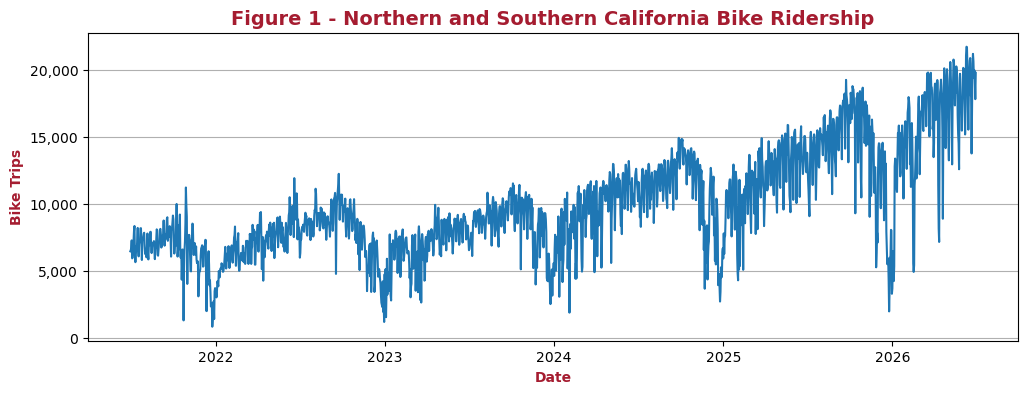

In [6]:
trips_by_date_df = bike_df\
    .groupby(['date', 'month', 'quarter'], as_index = False)\
    .agg(daily_trips = ('trip', 'sum'))

fig, ax = plt.subplots(figsize = (12, 4))
ax.set_title('Figure 1 - Northern and Southern California Bike Ridership', fontdict = title_large_font_dict)
ax.plot(trips_by_date_df['date'], trips_by_date_df['daily_trips'])
ax.set_ylabel('Bike Trips', fontdict = axis_font_dict)
ax.set_xlabel('Date', fontdict = axis_font_dict)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, pos: f'{y:,.0f}'))
plt.grid(axis = 'y')
plt.show()

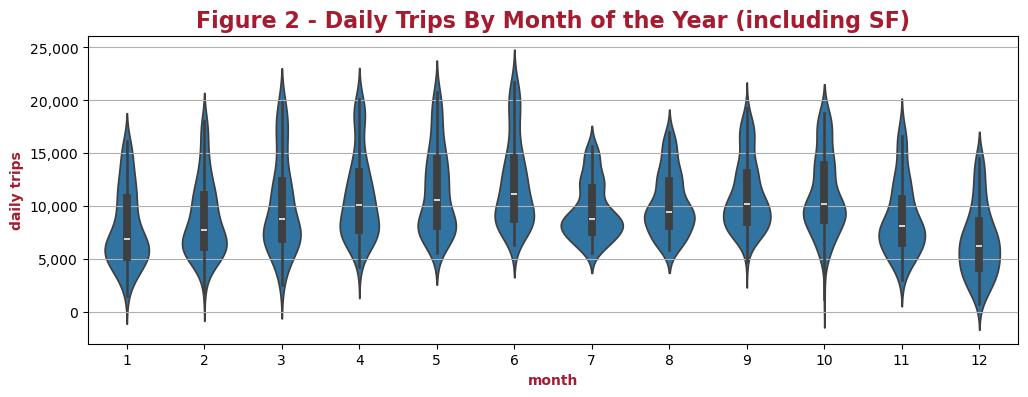

In [7]:
eda_violin_fun({'data': trips_by_date_df,
                'x': 'month',
                'y': 'daily_trips',
                'title': 'Figure 2 - Daily Trips By Month of the Year (including SF)',
                'figsize': (12, 4),
                'format': '{x:,.0f}'})

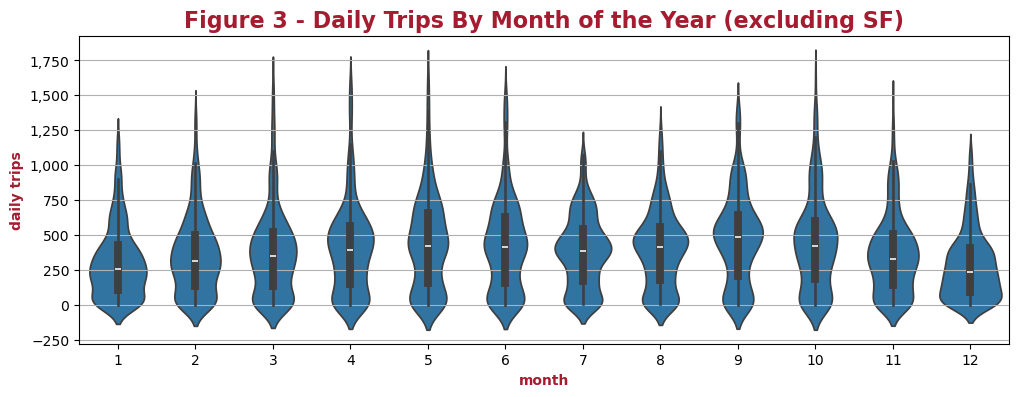

In [8]:
trips_by_date_df = bike_df\
    .query('start_region != "San Francisco"')\
    .groupby(['cal_region', 'start_region', 'date', 'month'], as_index = False)\
    .agg(daily_trips = ('trip', 'sum'))

eda_violin_fun({'data': trips_by_date_df,
                'x': 'month',
                'y': 'daily_trips',
                'title': 'Figure 3 - Daily Trips By Month of the Year (excluding SF)',
                'figsize': (12, 4),
                'format': '{x:,.0f}'})

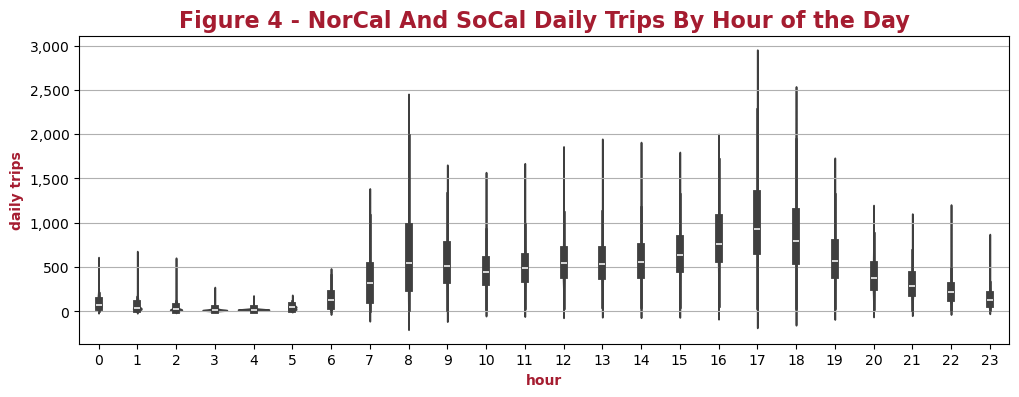

In [9]:
trips_by_hour_df = bike_df\
    .groupby(['date', 'month', 'hour'], as_index = False)\
    .agg(daily_trips = ('trip', 'sum'))

eda_violin_fun({'data': trips_by_hour_df,
                'x': 'hour',
                'y': 'daily_trips',
                'title': 'Figure 4 - NorCal And SoCal Daily Trips By Hour of the Day',
                'figsize': (12, 4),
                'format': '{x:,.0f}'})

## Trip Duration
<a id="eda_duration"></a>

Trip duration is measured in minutes. The median trip lasts 10 minutes, with a distribution that is right-skewed and that we capped at 2 hours. Under the boxplot interquartile range (IQR) rule, the 6.1% of trips exceeding 32 minutes would be classified as outliers. The skewness of trip duration, shown in **Figure 5**, warrants a logarithmic transformation to better approximate a normal distribution.

Several relationships were examined under the assumption that trip duration is influenced by time of day, day of the week, and user type. **Figure 6** presents the distribution of log trip duration by the hour at which a trip began, stratified by weekday and weekend. Weekend trips tend to be longer than weekday trips, and this difference appears most pronounced for trips beginning in the late morning through the early evening.

**Figure 7** presents the same relationship stratified by user type, where the differences are more pronounced. Trip duration among **Member** (subscriber) riders is relatively stable and varies little across the day. In contrast, trip duration among **Casual** (one-time) riders rises markedly depending on the time of day. This contrast suggests that members use the service for routine trips to and from the same stations, whereas casual riders are more likely to ride for leisure.

**Figure 8** illustrates an intuitive relationship: round trips tend to be longer than one-way trips, as one would reasonably expect. Additionally, trips from Friday (weekday 4) thru Sunday (weekday 6) have longer right tails again supporting the hypothesis that weekend trips are longer than weekday trips.

**Figure 9** displays log trip duration by day of the week, stratified by state region. Trips in Northern California appear shorter than those in Southern California, which is consistent with expectation, as Southern California cities are generally less dense and spread out across a larger area than those of the Bay Area.

[Return to contents](#contents)

Skew             Right Skew. Mean (13) > Median (10)
IQR                                        6 thru 16
Range                                     1 thru 120
Outlier Range                            nan thru 32
Outlier %                                       6.1%


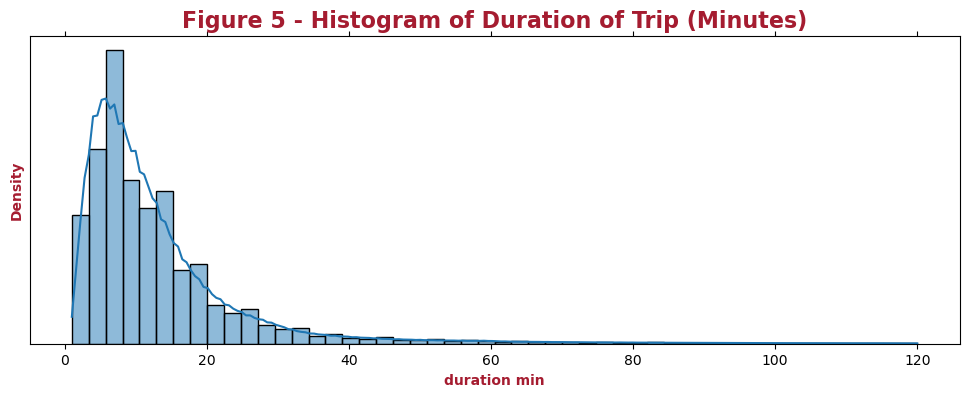

In [10]:
iqr_fun(bike_df, 'duration_min', ',.0f')

eda_hist_fun({'data': bike_df,
              'column': 'duration_min',
              'title': 'Figure 5 - Histogram of Duration of Trip (Minutes)',
              'format': ',.0f',
              'figsize': (12, 4),
              'bin_num': 50});

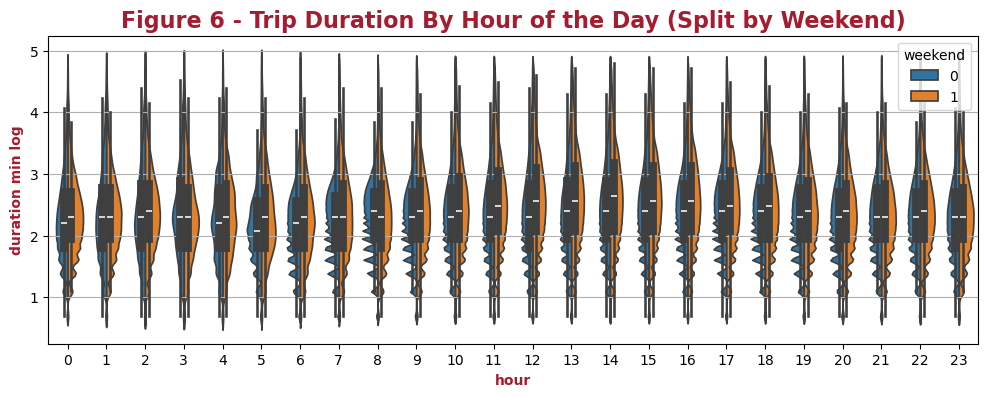

In [11]:
eda_violin_fun({'data': bike_df,
                'x': 'hour',
                'y': 'duration_min_log',
                'group': 'weekend',
                'title': 'Figure 6 - Trip Duration By Hour of the Day (Split by Weekend)',
                'figsize': (12, 4),
                'format': '{x:,.0f}'})

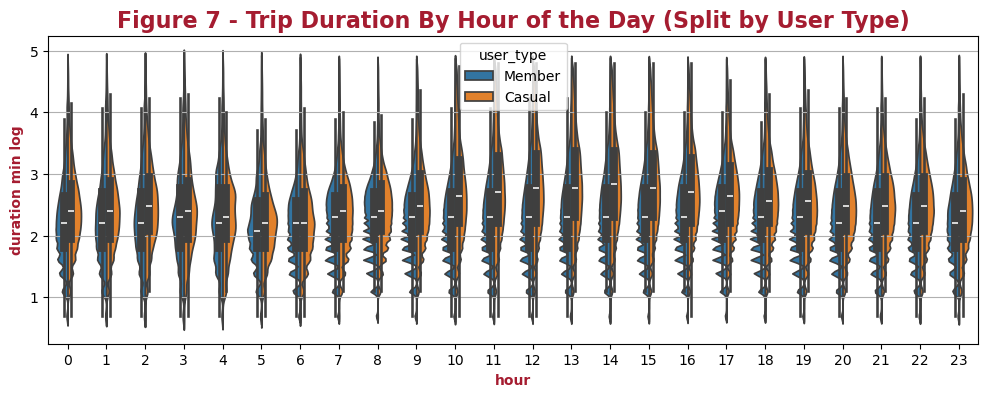

In [12]:
eda_violin_fun({'data': bike_df,
                'x': 'hour',
                'y': 'duration_min_log',
                'group': 'user_type',
                'title': 'Figure 7 - Trip Duration By Hour of the Day (Split by User Type)',
                'figsize': (12, 4),
                'format': '{x:,.0f}'})

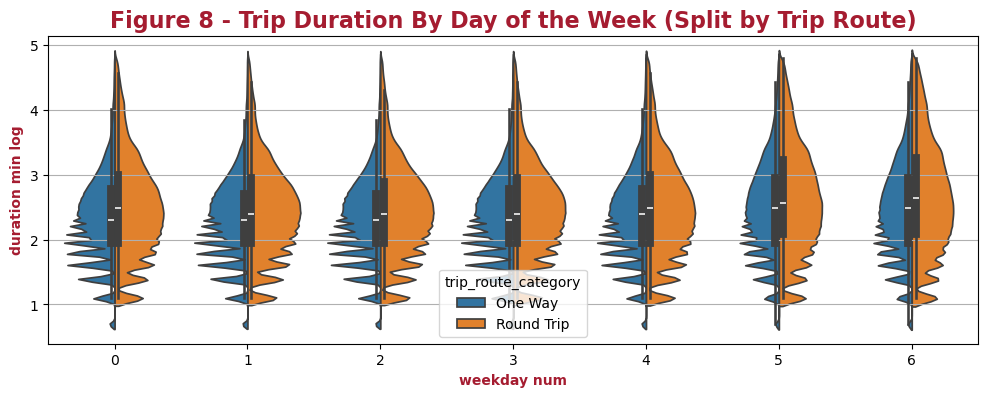

In [13]:
eda_violin_fun({'data': bike_df,
                'x': 'weekday_num',
                'y': 'duration_min_log',
                'group': 'trip_route_category',
                'title': 'Figure 8 - Trip Duration By Day of the Week (Split by Trip Route)',
                'figsize': (12, 4),
                'format': '{x:,.0f}'})

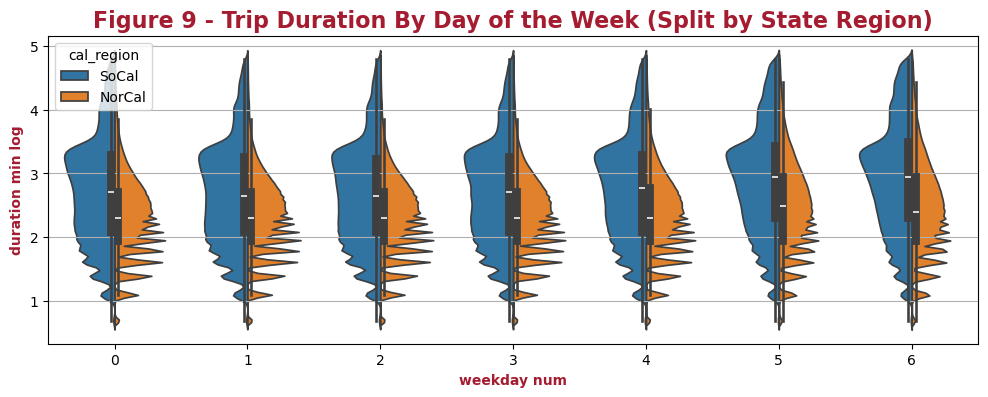

In [14]:
eda_violin_fun({'data': bike_df,
                'x': 'weekday_num',
                'y': 'duration_min_log',
                'group': 'cal_region',
                'title': 'Figure 9 - Trip Duration By Day of the Week (Split by State Region)',
                'figsize': (12, 4),
                'format': '{x:,.0f}'})

## Trip Distance
<a id="eda_distance"></a>

Estimated trip distance and trip speed were derived from the straight-line distance between a trip’s starting and ending coordinates and the time taken to complete it. Consequently, these measures are available only for one-way trips, as distance cannot be calculated for round trips, whose start and end stations are identical.

The median trip covers 1.1 miles, and the distribution of trip distance is right-skewed, with some trips spanning as much as 15 miles between stations. 3% of trips exceeding 3.3 miles would be classified as outliers under the boxplot interquartile range (IQR) rule. The skewness of trip distance, shown in **Figure 10**, warrants a logarithmic transformation to better approximate a normal distribution.

As **Figure 11** again demonstrates, trip duration is a key point of separation between Casual (one-time) riders and recurring Members (subscribers) of the bike sharing program. Casual riders log noticeably longer trips throughout the day, with the gap widening during the late morning and early afternoon, when leisure riding likely peaks. Members, by contrast, maintain shorter and more consistent trip lengths, which is characteristic of routine, utilitarian use. This reinforces the broader finding that the two groups use the service for fundamentally different purposes.

[Return to contents](#contents)

In [15]:
bike_oneway_df = bike_df[bike_df['trip_route_category'] == 'One Way']

Skew             Right Skew. Mean (1.3) > Median (1.1)
IQR                                       0.6 thru 1.7
Range                                    0.0 thru 14.7
Outlier Range                             nan thru 3.3
Outlier %                                         3.0%


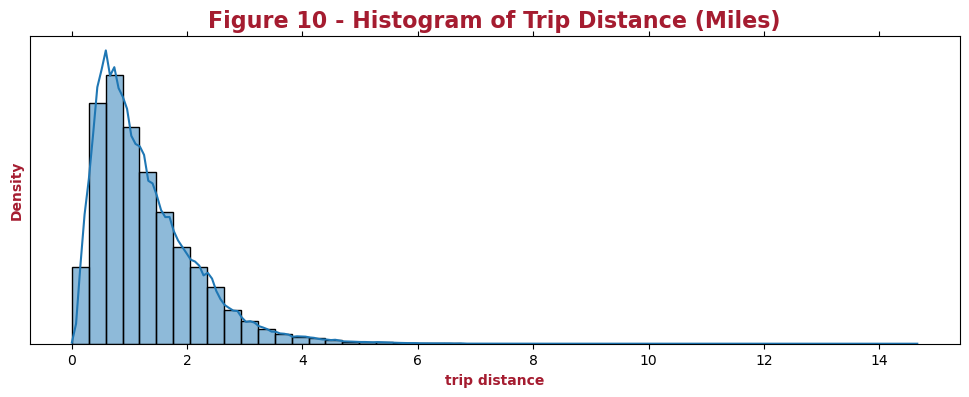

In [16]:
iqr_fun(bike_oneway_df, 'trip_distance', ',.1f')
eda_hist_fun({'data': bike_oneway_df,
              'column': 'trip_distance',
              'title': 'Figure 10 - Histogram of Trip Distance (Miles)',
              'format': ',.0f',
              'figsize': (12, 4),
              'bin_num': 50});

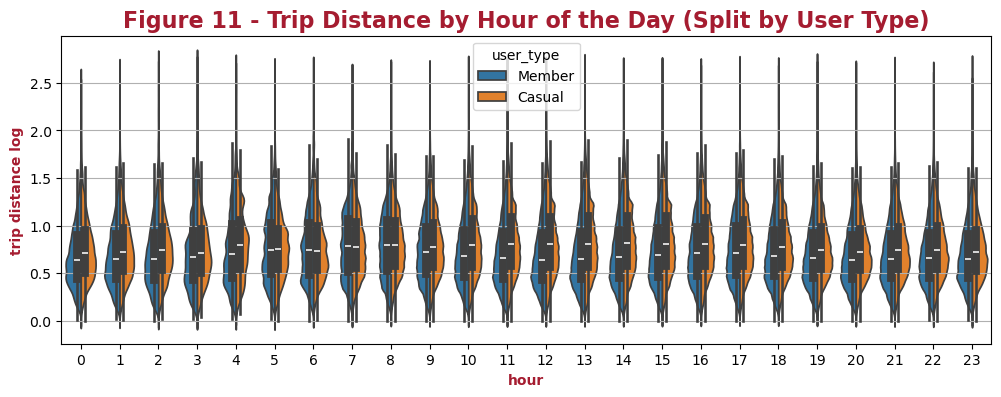

In [17]:
eda_violin_fun({'data': bike_oneway_df,
                'x': 'hour',
                'y': 'trip_distance_log',
                'group': 'user_type',
                'title': 'Figure 11 - Trip Distance by Hour of the Day (Split by User Type)',
                'figsize': (12, 4),
                'format': '{x:,.1f}'})

## Trip Speed
<a id="eda_speed"></a>

The middle 50% of trips have speeds between 5 and 9 mph, and trips faster than 14 mph can be considered outliers, which supports the decision to exclude trips faster than 20 mph. The distribution of trip speed closely approximates a normal distribution, as shown in **Figure 12**.

**Figure 13** examines whether trips on electric bikes are faster than trips on traditional bikes. In every region except Downtown Los Angeles (DTLA), electric bike trips are indeed faster. In DTLA, electric bike trips follow a bimodal speed distribution, a pattern also visible, to a lesser degree, in two other Southern California regions, Westside and North Hollywood. The presence of a large number of very slow one-way trips, particularly when confined to Southern California, may be the result of how estimated speed is calculated and the way duration is recorded across regions. In Northern California, timestamps are recorded down to the second, while in Southern California the trip duration is in 1 minute increments, which makes the speed calculation a little less accurate in Southern California.

**Figure 14** reveals a counterintuitive relationship between trip speed and federal holidays. Because vehicular traffic is presumably lighter on federal holidays than on ordinary days, one might expect bike riders to be able to travel faster, unimpeded by congestion. The data show the opposite: trips taken on federal holidays are slower on average than those taken on non-holidays. One plausible explanation is a shift in rider composition. Holidays may attract more leisure and casual riders, who tend to travel at a slower pace and make more stops than commuters do. This interpretation is consistent with the earlier finding that casual riders take longer trips (**Figure 6**), though further analysis would be needed to confirm it.

[Return to contents](#contents)

Skew             Right Skew. Mean (7) > Median (7)
IQR                                       5 thru 9
Range                                    0 thru 20
Outlier Range                            0 thru 14
Outlier %                                     0.7%


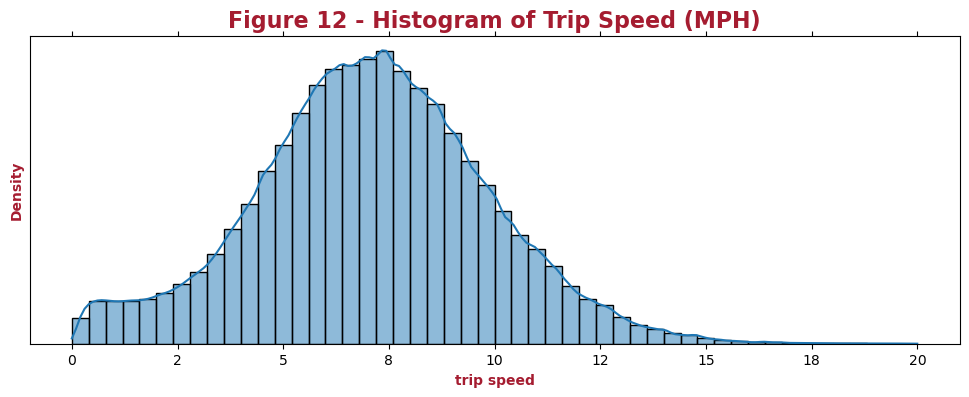

In [18]:
iqr_fun(bike_oneway_df, 'trip_speed', ',.0f')
eda_hist_fun({'data': bike_oneway_df,
              'column': 'trip_speed',
              'title': 'Figure 12 - Histogram of Trip Speed (MPH)',
              'format': ',.0f',
              'figsize': (12, 4),
              'bin_num': 50});

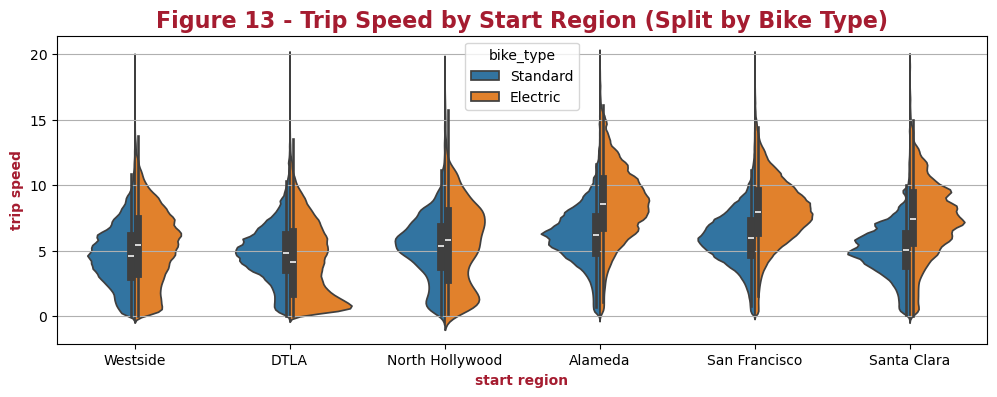

In [19]:
eda_violin_fun({'data': bike_oneway_df,
                'x': 'start_region',
                'y': 'trip_speed',
                'group': 'bike_type',
                'title': 'Figure 13 - Trip Speed by Start Region (Split by Bike Type)',
                'figsize': (12, 4),
                'format': '{x:,.0f}'})

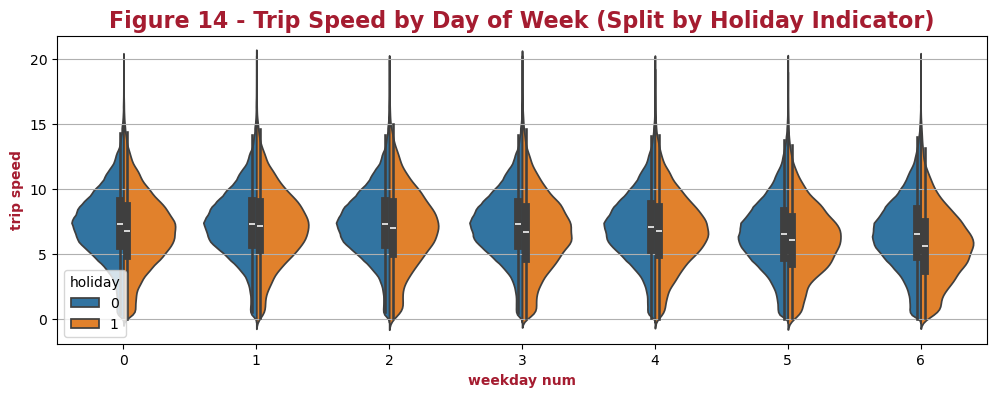

In [20]:
eda_violin_fun({'data': bike_oneway_df,
                'x': 'weekday_num',
                'y': 'trip_speed',
                'group': 'holiday',
                'title': 'Figure 14 - Trip Speed by Day of Week (Split by Holiday Indicator)',
                'figsize': (12, 4),
                'format': '{x:,.0f}'})

## Top Station-to-Station Routes
<a id="eda_stations"></a>

**Southern California**

A look at the most popular station-to-station routes in Southern California reveals several distinct patterns of use.
1. **Multimodal commuting**. 8 of the 20 routes begin or end at the western terminus of the Metro E Line in Santa Monica. This suggests that many riders combine transit with biking, taking the train for the long haul and a bike share bike for the final leg of the trip. An additional trip from Downtown LA to Union Station supports this conclusion as Union Station is the hub for regional rail connections.
2. **Student travel**. Another 7 routes start or end at a university campus, either UCLA in Westwood or USC just north of Exposition Park near downtown Los Angeles. These trips likely reflect students getting around campus and the surrounding neighborhoods.
3. **Recreational riding**. The remaining routes include scenic trips along the coast, particularly in Venice and El Segundo. Here the ride itself is often the destination, and beachfront paths draw riders out for leisure as much as transportation.

Together, these patterns show that bike share in Southern California serves commuters, students, and weekend cruisers alike.

**Northern California**

The most popular station-to-station routes in Northern California are heavily centered on San Francisco’s downtown core, with a few clear patterns.

1. **The Embarcadero hub**. 13 of the top 20 routes start or end at Embarcadero Plaza, the first Bay Area Rapid Transit (BART) stop inside the city and the heart of a dense office district. From this hub, two dominant paths emerge. One heads toward Pier 39, one of the city’s busiest tourist destinations, suggesting leisure riders exploring the waterfront. The other leads to the Caltrain station, a pattern consistent with commuters bridging the gap between regional rail and the workplace, particularly those who live farther out and transfer between systems on their way to work.
2. **Oakland connections**. 4 routes begin or end at the 19th Street Oakland BART station and cover relatively short distances from there. This suggests riders who combine transit with biking for the last leg of their trip, traveling to and from destinations around Oakland.
3. **Parks and city streets**. The remaining routes split between two very different kinds of riding: relaxed leisure trips through Golden Gate Park, and commuters cutting along Market Street, the city’s main downtown artery.

Taken together, the data shows bike share working as both a first-and-last-mile connector for commuters and a way for visitors and residents to enjoy the city.

[Return to contents](#contents)

In [21]:
plot_df = station_to_station_fun(bike_df, 'SoCal', top_n = 20)
station_to_station_plot_fun(plot_df, num_cols = 4, num_rows = 5, w = 1200, h = 1000, z = 13)

Top 20 Station-to-Station Routes in SoCal



In [22]:
plot_df = station_to_station_fun(bike_df, 'NorCal', top_n = 20)
station_to_station_plot_fun(plot_df, num_cols = 4, num_rows = 5, w = 1200, h = 1000, z = 13)

Top 20 Station-to-Station Routes in NorCal



# Part 1 - Modeling Seasonal and Diurnal Effects
<a id="seasonality"></a>

We begin by estimating seasonal (year and month) and diurnal (hour of the day) effects on bike ridership across both regions in California. To accurately calculate diurnal effects, we need to construct a complete dataset of all combinations of start regions, dates, and hours present in the data. Combinations with no recorded rides were retained with a count of zero, so that low-demand periods are not omitted from the analysis.

[Return to contents](#contents)

In [23]:
# Complete grid of trips by day-hour-region
hourly_trips_df = bike_df\
    .groupby(['start_region', 'date', 'hour_block'], as_index = False)\
    .agg(trips = ('trip', 'sum'))

dates_df = pd.DataFrame({'date': pd.date_range(start = bike_df['date'].min(), end = bike_df['date'].max())})
dates_df['month'] = dates_df['date'].dt.month
dates_df['bike_year'] = [d.year + 1 if d.month >= 7 else d.year for d in dates_df['date']]
hours_df = bike_df[['hour_block']].drop_duplicates()
regions_df = bike_df[['start_region']].drop_duplicates()
hourly_trips_df = dates_df\
    .merge(hours_df, how = 'cross')\
    .merge(regions_df, how = 'cross')\
    .merge(hourly_trips_df, on = ['date', 'hour_block', 'start_region'], how = 'left')\
    .sort_values(by = ['date', 'hour_block', 'start_region'])\
    .reset_index(drop = True)
hourly_trips_df['trips'] = hourly_trips_df['trips'].fillna(0).astype(int)

if ((hourly_trips_df['date'].max() - hourly_trips_df['date'].min()).days + 1) * hours_df.shape[0] * regions_df.shape[0] == hourly_trips_df.shape[0]:
    print('Dateset complete: ' + format(sum(hourly_trips_df['trips'] == 0), ',.0f') + ' rows with 0 trips inserted. ' + 
        format(hourly_trips_df.shape[0], ',.0f') + ' total rows.\n')
else:
    print('Number of rows unexpected')

hourly_trips_df.head(5)

Dateset complete: 4,743 rows with 0 trips inserted. 65,736 total rows.



,date,month,bike_year,hour_block,start_region,trips
0,2021-07-01,7,2022,Early Morning,Alameda,29
1,2021-07-01,7,2022,Early Morning,DTLA,15
2,2021-07-01,7,2022,Early Morning,North Hollywood,0
3,2021-07-01,7,2022,Early Morning,San Francisco,358
4,2021-07-01,7,2022,Early Morning,Santa Clara,18


## Trips GLM Model (Poisson)
<a id="trips_glm_poisson"></a>

Because ride counts are non-negative integers, we start with a Poisson GLM with a log link. Poisson assumes the variance equals the mean, so we first test whether that assumption holds.

We assess dispersion by dividing the Pearson chi-square by the residual degrees of freedom. A ratio near 1 supports the Poisson assumption, a ratio well above 1 indicates overdispersion, and a ratio well below 1 indicates underdispersion. Here the ratio was roughly 38, indicating severe overdispersion that makes the Poisson standard errors far too small. We therefore use a Negative Binomial GLM, which allows the variance to grow quadratically with the mean, and estimate the dispersion parameter alpha by maximum likelihood.

[Return to contents](#contents)

In [24]:
trips_formula = "trips ~ C(bike_year, Treatment(reference = 2022))\
    + C(month, Treatment(reference = 1))\
    + C(start_region, Treatment(reference = 'Alameda'))\
    + C(hour_block, Treatment(reference = 'Midday'))"

trips_glm_poisson = smf.glm(formula = trips_formula,
                            data = hourly_trips_df,
                            family = sm.families.Poisson()).fit()
print(trips_glm_poisson.summary())

# Check for dispersion
glm_dispersion = trips_glm_poisson.pearson_chi2 / trips_glm_poisson.df_resid
print("Dispersion Parameter:", glm_dispersion)

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  trips   No. Observations:                65736
Model:                            GLM   Df Residuals:                    65710
Model Family:                 Poisson   Df Model:                           25
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.4303e+06
Date:                Thu, 19 Nov 2026   Deviance:                   2.5050e+06
Time:                        13:56:46   Pearson chi2:                 2.53e+06
No. Iterations:                     9   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                                                                         coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------

## Trips GLM Model (Negative Binomial)
<a id="trips_glm_nb"></a>

The Negative Binomial model substantially improves on the Poisson fit, with a Pearson chi-square to residual degrees of freedom ratio of 1.205, close to the ideal of 1. Residual diagnostics in **Figure 15** show the model captures the bulk of the data but not all of its structure: residual spread is larger at low predicted means and narrows at high ones, and the QQ plot reveals a heavy right tail driven by a small number of extreme observations. We therefore treat the Negative Binomial variance function as an adequate but imperfect approximation and report heteroscedasticity-robust (HC3) standard errors and further investigate the influential observations to better understand the outliers.

The extreme residuals in the QQ plot are examined further below.

[Return to contents](#contents)

Negative Binomial Dispersion Parameter: 1.205
Negative Binomial Alpha = 0.264
Negative Binomial AIC = 606,999.3
                     NegativeBinomial Regression Results                      
Dep. Variable:                  trips   No. Observations:                65736
Model:               NegativeBinomial   Df Residuals:                    65710
Method:                           MLE   Df Model:                           25
Date:                Thu, 19 Nov 2026   Pseudo R-squ.:                  0.2250
Time:                        13:56:47   Log-Likelihood:            -3.0347e+05
converged:                       True   LL-Null:                   -3.9155e+05
Covariance Type:                  HC3   LLR p-value:                     0.000
                                                                         coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------------

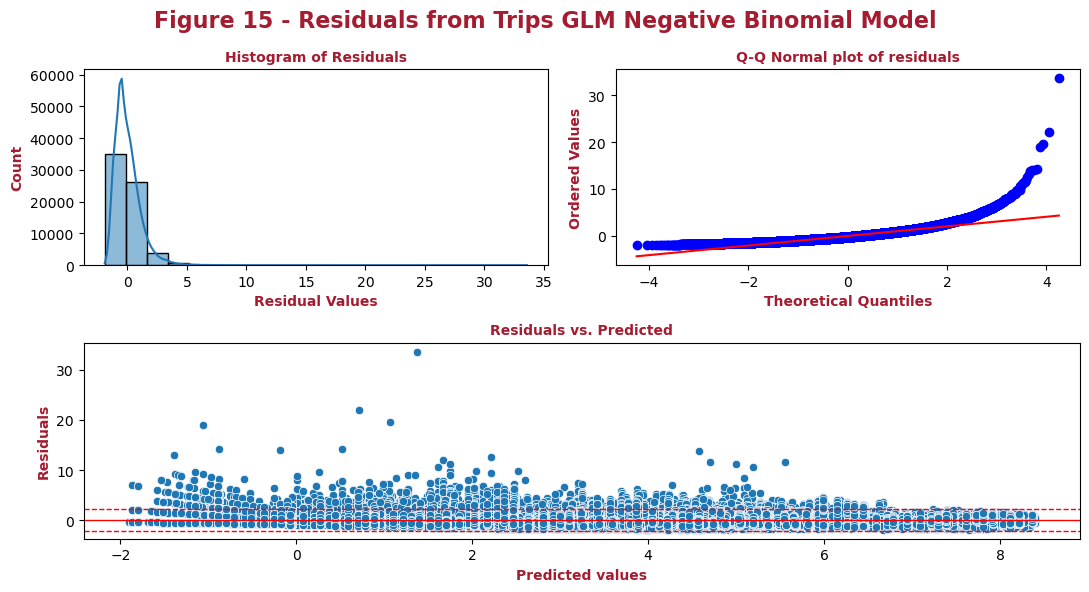

In [25]:
trips_glm_nb = smf.negativebinomial(formula = trips_formula,
                                    data = hourly_trips_df).fit(disp = False,
                                                                maxiter = 200,
                                                                cov_type = 'HC3')

# The ratio of deviance to degrees of freedom when using Statsmodels NegativeBinomial
trips_glm_nb_mu = trips_glm_nb.predict()
trips_glm_nb_alpha = trips_glm_nb.params['alpha']
trips_glm_nb_y = hourly_trips_df['trips']

trips_glm_nb_pearson = (trips_glm_nb_y - trips_glm_nb_mu) / np.sqrt(trips_glm_nb_mu + trips_glm_nb_alpha * trips_glm_nb_mu**2)
glm_nb_dispersion = (trips_glm_nb_pearson**2).sum() / trips_glm_nb.df_resid
print("Negative Binomial Dispersion Parameter:", format(glm_nb_dispersion, '.3f'))
print(format('Negative Binomial Alpha = ' + str(format(trips_glm_nb_alpha, '.3f'))))
print(format('Negative Binomial AIC = ' + str(format(trips_glm_nb.aic, ',.1f'))))
print(trips_glm_nb.summary())

# Plots
plot_resid_fun({'prediction': trips_glm_nb.fittedvalues,
                'residuals': trips_glm_nb.resid_pearson,
                'title': 'Figure 15 - Residuals from Trips GLM Negative Binomial Model',
                'figsize': (11, 6)});

## Year, Month and Hour Block Effects
<a id="month_year_effects"></a>

The reference category was a midday trip on January 2022 in Alameda County, for which the model predicts approximately 91 trips. 

The **bike year** percent change in **Figure 16** supports our initial assertion that bike sharing in California is growing. Every year shows a statistically significant increase over the baseline bike year (2022), and the estimates rise steadily: +3.5% in 2023, +38% in 2024, +69% in 2025, and by 2026, ridership was 98.5% higher than in the baseline year, or roughly 2 times as large.

**Figure 17** shows the percent change in ridership by **month** relative to January, the baseline. Ridership follows a winter trough (December, January, and February), rises through the spring, and peaks in June. In July, however, ridership drops, which breaks the expected seasonal pattern. We hypothesize that San Francisco’s unusual summer weather is driving this dip, since San Francisco is the largest region in the dataset, as confirmed by the region's 1206.7% effect. **We test this hypothesis next.**

As shown in **Figure 18**, relative to the baseline, and holding all other covariates constant:
1. **Early Morning**: about 83% fewer trips.
2. **Morning**: about 26% fewer trips.
3. **PM Peak**: about 16% more trips.
4. **Late Evening**: about 56% fewer trips.
5. **Overnight**: about 91% fewer trips.

The patterns we saw earlier in **Figure 4** are statistically significant and confirm that demand peaks in the PM Peak block and is lowest overnight.

[Return to contents](#contents)

In [26]:
# Model Coefficients and Effects
glm_nb_coeffs_df = model_coeff_fun(trips_glm_nb)
glm_nb_effects_df = model_coeff_fun(trips_glm_nb, log = True)
glm_nb_effects_df['color'] = ['green' if c else 'red' for c in glm_nb_effects_df['sign']]
glm_nb_effects_df['height'] = glm_nb_effects_df['effect_975'] - glm_nb_effects_df['effect_025']

hourly_glm_nb_intercept = glm_nb_coeffs_df[glm_nb_coeffs_df['coef_name'] == 'Intercept']['coef'].iloc[0]
hourly_glm_nb_avg_rides = np.exp(hourly_glm_nb_intercept)
print('Average Rides by Hour Block: ' + str(format(hourly_glm_nb_avg_rides, '.0f')) + '\n')

glm_nb_effects_df.drop(['color', 'height'], axis = 1)

Average Rides by Hour Block: 91



,effect_name,effect_ref,p_value,sign,effect,effect_025,effect_975
0,bike_year_2023,2022,0.000,True,0.034895,0.020201,0.050220
1,bike_year_2024,2022,0.000,True,0.382786,0.362062,0.403543
2,bike_year_2025,2022,0.000,True,0.686913,0.663627,0.710867
3,bike_year_2026,2022,0.000,True,0.984764,0.956193,1.013753
4,month_2,1,0.000,True,0.161718,0.134282,0.188866
5,month_3,1,0.000,True,0.304344,0.273794,0.335092
6,month_4,1,0.000,True,0.418500,0.386801,0.450633
7,month_5,1,0.000,True,0.580277,0.544963,0.616074
8,month_6,1,0.000,True,0.560802,0.526534,0.595201
9,month_7,1,0.000,True,0.324719,0.295634,0.355269


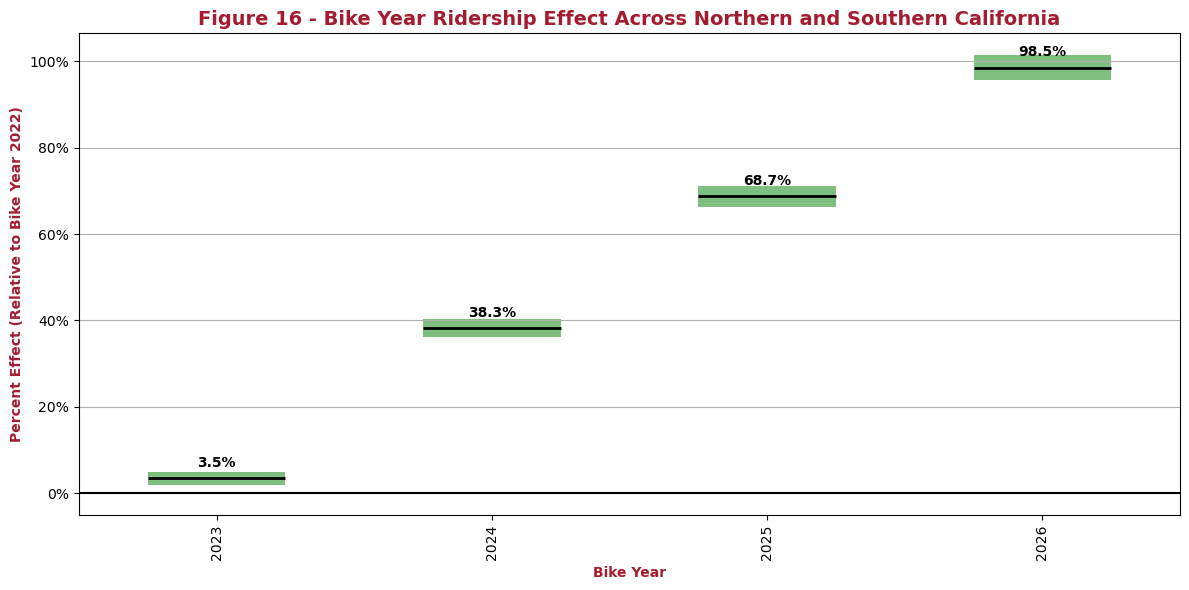

In [27]:
# Plot Year Coefficients
plot_df = glm_nb_effects_df[(glm_nb_effects_df['effect_name'].str.contains('bike_year'))]
plot_df['effect_name'] = plot_df['effect_name'].str.replace('bike_year_', '')

plot_effects_fun({'data': plot_df,
                  'x': 'effect_name',
                  'bar_min': 'effect_025',
                  'bar_label': 'effect',
                  'bar_height': 'height',                  
                  'y_label': 'Percent Effect (Relative to Bike Year 2022)',
                  'x_label': 'Bike Year',
                  'title': 'Figure 16 - Bike Year Ridership Effect Across Northern and Southern California',
                  'figsize': (12, 6)});

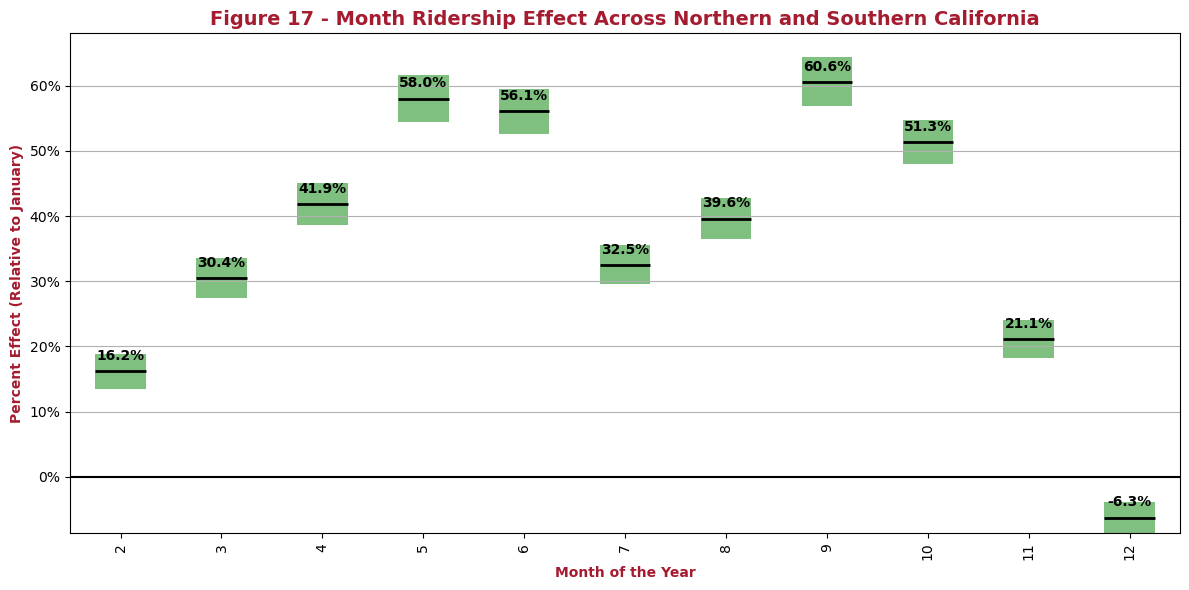

In [28]:
# Plot Monthly Coefficients
plot_df = glm_nb_effects_df[(glm_nb_effects_df['effect_name'].str.contains('month'))]
plot_df['effect_name'] = plot_df['effect_name'].str.replace('month_', '')

plot_effects_fun({'data': plot_df,
                  'x': 'effect_name',
                  'bar_min': 'effect_025',
                  'bar_label': 'effect',
                  'bar_height': 'height',                  
                  'y_label': 'Percent Effect (Relative to January)',
                  'x_label': 'Month of the Year',
                  'title': 'Figure 17 - Month Ridership Effect Across Northern and Southern California',
                  'figsize': (12, 6)});

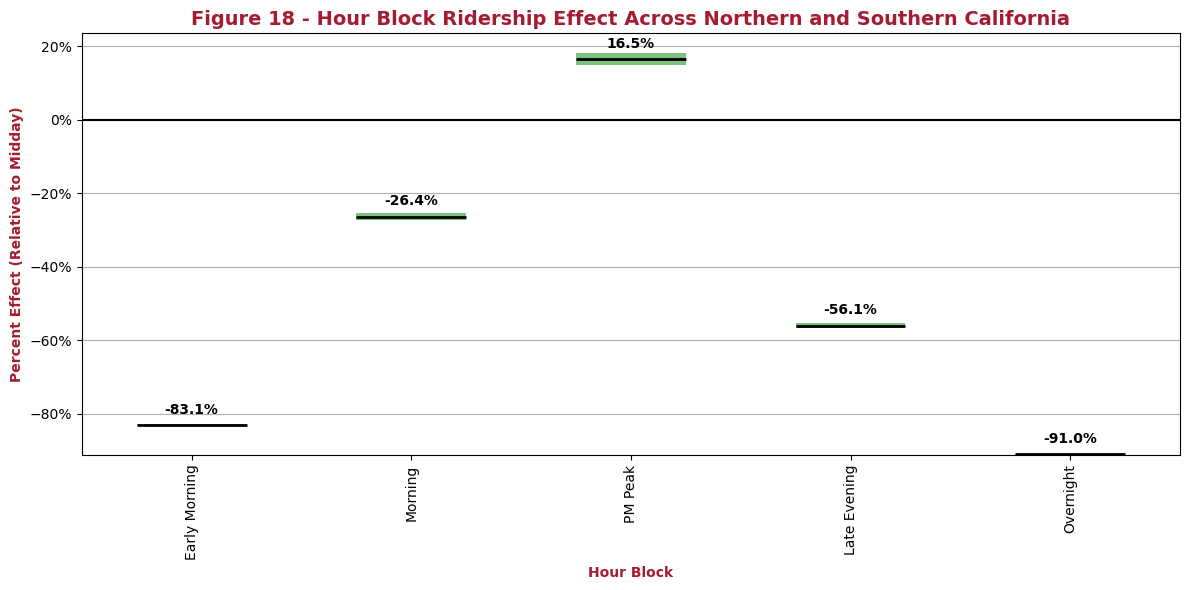

In [29]:
# Plot Hour Coefficients
plot_df = glm_nb_effects_df[(glm_nb_effects_df['effect_name'].str.contains('hour_block'))]
plot_df['effect_name'] = plot_df['effect_name'].str.replace('hour_block_', '')
plot_df['order'] = plot_df['effect_name'].map({'Early Morning': 1,
                                               'Morning': 2,
                                               'PM Peak': 3,
                                               'Late Evening': 4,
                                               'Overnight': 5})

plot_effects_fun({'data': plot_df.sort_values(by = 'order'),
                  'x': 'effect_name',
                  'bar_min': 'effect_025',
                  'bar_label': 'effect',
                  'bar_height': 'height',                  
                  'y_label': 'Percent Effect (Relative to Midday)',
                  'x_label': 'Hour Block',
                  'title': 'Figure 18 - Hour Block Ridership Effect Across Northern and Southern California',
                  'figsize': (12, 6)});

## Bootstrapped Summer Coefficients by Region
### Was Mark Twain right? Is the Coldest Winter Really a San Francisco Summer?
<a id="effects_mark_twain"></a>

To test the hypothesis that the July decline in ridership is specific to San Francisco, we employed a nonparametric bootstrap. Prior to conducting the hypothesis test, we first verified that the July effect estimated via bootstrap was consistent with that obtained from the negative binomial generalized linear model (GLM). Agreement between the two approaches would indicate that the bootstrap procedure is a valid basis for subsequent inference.

**Figure 19** shows the distribution of the July effect across 500 bootstrap resamples. Given the size of our dataset, this number of resamples produced stable estimates, comparable to those obtained with a larger number of resamples. The bootstrap mean effect (32.5%) matched the GLM point estimate (32.5%). The bootstrap 95% confidence interval (29.6% to 35.65%) also matched the corresponding GLM interval (29.6% to 35.5%). Given this concordance in point estimates, we proceeded with the bootstrap to estimate effects for San Francisco and to compare them with those of other regions.

For the regional analysis, we adjust the model's formula such that June is the reference month, ensuring that the July and August effects are expressed relative to June ridership. We will then resample the same dates for all regions, since on a give day regions close to each other experience the same weather, and holidays and events are also correlated. Bootstrapping each region separately would treat them as independent.

As shown in **Figure 20**, every region except Santa Clara also experienced a decline in ridership from June to July, and the decline in San Francisco (-19%) was not even the most pronouned. The largest decline happend in North Hollywood, which saw a 39% decline in ridership. Alameda, Downtown LA, and the Westside had declines in ridership between 12% and 22%. **Figure 21** shows a similar pattern for August relative to June: declines were generally smaller than in July in all regions, and Santa Clara was the exception, with an increase of 10% in ridership.

These results do not support our initial hypothesis that given the prominence of San Francisco in the dataset, that the fog in the city explains the July decline in ridership. A decline of comparable magnitude appears in most regions of the state, so it is unlikely to originate in a single region. Our data contain no weather measurements, so we cannot test the fog explanation directly. We can only conclude that the decline is not confined to San Francisco.

[Return to contents](#contents)

In [30]:
# GLM effects for July
glm_nb_effects_df[(glm_nb_effects_df['effect_name'] == 'month_7')].drop(['color', 'height'], axis = 1)

,effect_name,effect_ref,p_value,sign,effect,effect_025,effect_975
9,month_7,1,0.000,True,0.324719,0.295634,0.355269


In [31]:
print(" ".join(trips_formula.split()))
print('\nBased on ' + format(part1_bs_n, ',.0f') + ' bootstrap samples\n')

# Set seed and random states for reproducibility
n_samples = hourly_trips_df.shape[0]
random.seed(42)
random_states = [random.randint(0, 1000) for i in range(part1_bs_n)]

# Bootstrap coefficients
bs_effects_df = pd.DataFrame()
for bs, r in zip(range(part1_bs_n), random_states):
    # Bootstrap Sample
    bs_df = hourly_trips_df.sample(n = n_samples, replace = True, random_state = r)
    # Fit Negative Binomial Model 
    bs_glm_nb = smf.negativebinomial(formula = trips_formula,
                                     data = bs_df).fit(disp = False,
                                                       maxiter = 200,
                                                       cov_type = 'HC3')
    df = model_coeff_fun(bs_glm_nb, log = True)
    df['bs'] = bs
    bs_effects_df = pd.concat([bs_effects_df, df]).reset_index(drop = True)

bs_effects_df[(bs_effects_df['effect_name'] == 'month_7')].head()

trips ~ C(bike_year, Treatment(reference = 2022)) + C(month, Treatment(reference = 1)) + C(start_region, Treatment(reference = 'Alameda')) + C(hour_block, Treatment(reference = 'Midday'))

Based on 500 bootstrap samples



,effect_name,effect_ref,p_value,sign,effect,effect_025,effect_975,bs
9,month_7,1,0.000,True,0.334157,0.304735,0.363425,0
34,month_7,1,0.000,True,0.314820,0.286596,0.344470,1
59,month_7,1,0.000,True,0.334424,0.304735,0.364789,2
84,month_7,1,0.000,True,0.308786,0.278900,0.339103,3
109,month_7,1,0.000,True,0.320486,0.291753,0.349859,4


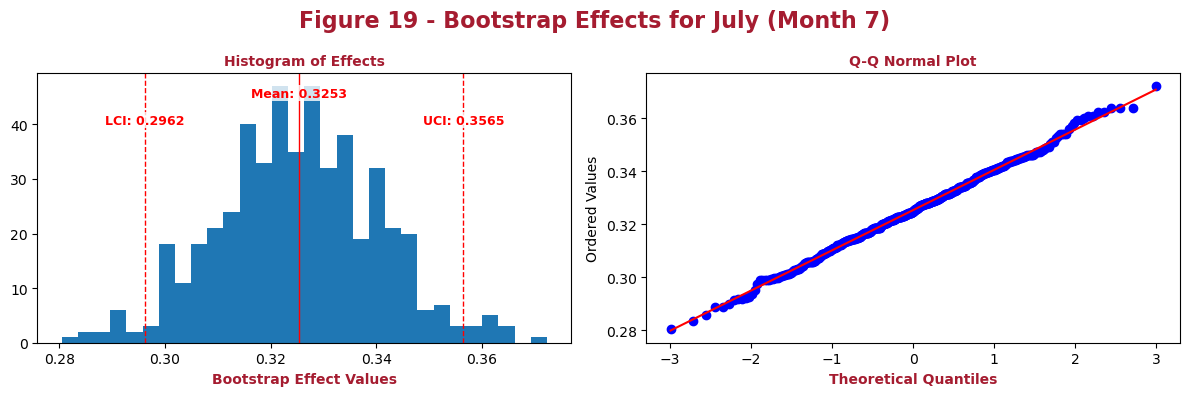

In [32]:
# Plot July Bootstrap Effects
plot_df = bs_effects_df[(bs_effects_df['effect_name'] == 'month_7')]

plot_bs_coeff_fun({'effects': plot_df['effect'],
                   'alpha': 0.05,
                   'title': 'Figure 19 - Bootstrap Effects for July (Month 7)',
                   'bins': 30,
                   'figsize': (12, 4)});

In [33]:
# Make June the Base Month
bs_formula = "trips ~ C(bike_year, Treatment(reference = 2022))\
    + C(month, Treatment(reference = 6))\
    + C(hour_block, Treatment(reference = 'Midday'))"
print(' '.join(bs_formula.split()), '\n')
print('\nBased on ' + format(part1_bs_n, ',.0f') + ' bootstrap samples\n')

# Bootstrap Effects by date and time of day
resample_by = ['date', 'hour_block']

# Set seed and random states for reproducibility
random.seed(1835)
random_states = [random.randint(0, 1000) for i in range(part1_bs_n)]

# Bootstrap resample the same dates for all regions
dates_df = hourly_trips_df[resample_by].drop_duplicates().reset_index(drop = True)
n_samples = dates_df.shape[0]
regions = sorted(set(hourly_trips_df['start_region']))

# Bootstrap coefficients
bs_region_effects_df = pd.DataFrame()
for bs, r in zip(range(part1_bs_n), random_states):
    # Resampling the same dates for all regions
    bs_dates_df = dates_df.sample(n = n_samples, replace = True, random_state = r)
    # Fit Negative Binomial Model on same dates across all regions
    for region in regions:
        bs_df = hourly_trips_df[hourly_trips_df['start_region'] == region].merge(bs_dates_df, on = resample_by, how = 'inner')
        bs_glm_nb = smf.negativebinomial(formula = bs_formula,
                                         data = bs_df).fit(disp = False,
                                                           maxiter = 200,
                                                           cov_type = 'HC3')
        df = model_coeff_fun(bs_glm_nb, log = True)
        df['bs'] = bs
        df['start_region'] = region
        bs_region_effects_df = pd.concat([bs_region_effects_df, df]).reset_index(drop = True)

bs_region_effects_df.head()

trips ~ C(bike_year, Treatment(reference = 2022)) + C(month, Treatment(reference = 6)) + C(hour_block, Treatment(reference = 'Midday')) 


Based on 500 bootstrap samples



,effect_name,effect_ref,p_value,sign,effect,effect_025,effect_975,bs,start_region
0,bike_year_2023,2022,0.000,True,-0.054177,-0.077806,-0.029554,0,Alameda
1,bike_year_2024,2022,0.000,True,0.049485,0.025315,0.074655,0,Alameda
2,bike_year_2025,2022,0.000,True,0.902179,0.858928,0.946436,0,Alameda
3,bike_year_2026,2022,0.000,True,1.632674,1.570242,1.696622,0,Alameda
4,month_1,6,0.000,True,-0.427247,-0.449539,-0.404289,0,Alameda


In [34]:
# Calculate July and August Effect CIs across all regions
bs_effects_ci_df = bs_region_effects_df\
    .query('effect_name in ("month_7", "month_8")')\
    .groupby(['start_region', 'effect_name', 'effect_ref'], as_index = False)\
    .agg(mean = ('effect', 'mean'),
         lci = ('effect', lambda x: np.percentile(x, 2.5)),
         uci = ('effect', lambda x: np.percentile(x, 97.5)))\
    .sort_values(by = ['effect_name', 'start_region'])\
    .reset_index(drop = True)
bs_effects_ci_df['sign'] = [(l * u) > 0 for l, u in zip(bs_effects_ci_df['lci'], bs_effects_ci_df['uci'])]
bs_effects_ci_df['color'] = ['green' if c else 'red' for c in bs_effects_ci_df['sign']]
bs_effects_ci_df['height'] = bs_effects_ci_df['uci'] - bs_effects_ci_df['lci']

bs_effects_ci_df.drop(['color', 'height'], axis = 1)

,start_region,effect_name,effect_ref,mean,lci,uci,sign
0,Alameda,month_7,6,-0.219517,-0.243082,-0.194663,True
1,DTLA,month_7,6,-0.120701,-0.140324,-0.097309,True
2,North Hollywood,month_7,6,-0.391503,-0.452152,-0.328725,True
3,San Francisco,month_7,6,-0.191785,-0.217841,-0.157836,True
4,Santa Clara,month_7,6,-0.012433,-0.053425,0.027422,False
5,Westside,month_7,6,-0.117488,-0.154308,-0.088442,True
6,Alameda,month_8,6,-0.137995,-0.164245,-0.112272,True
7,DTLA,month_8,6,-0.128587,-0.152615,-0.106329,True
8,North Hollywood,month_8,6,-0.377632,-0.436563,-0.311679,True
9,San Francisco,month_8,6,-0.144128,-0.172797,-0.113612,True


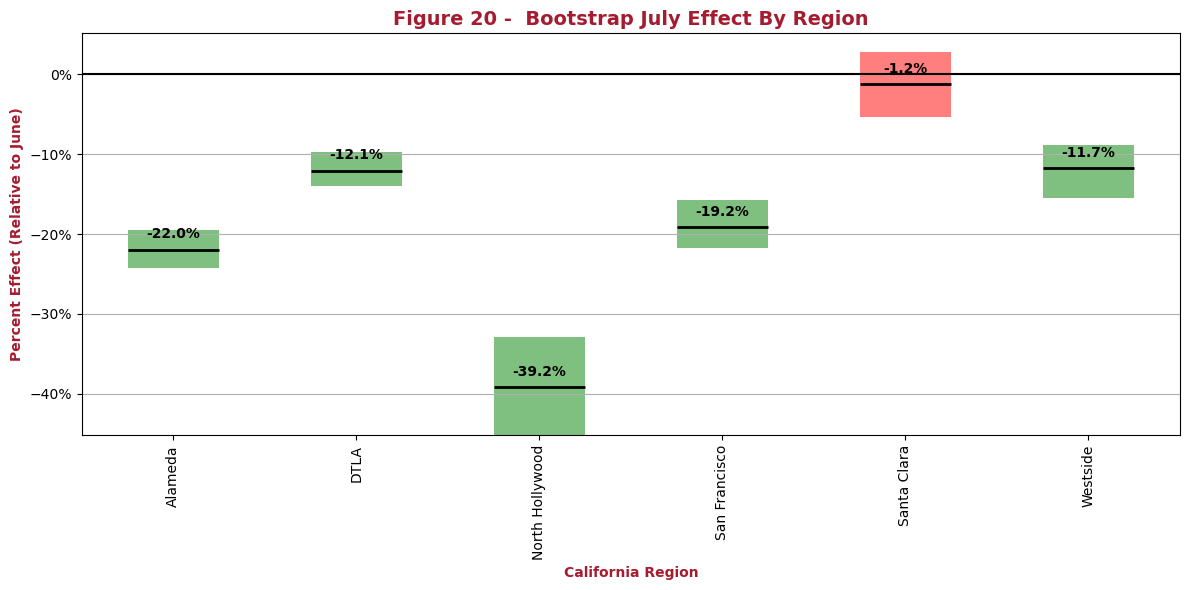

In [35]:
# Plot effects for July across all regions
plot_df = bs_effects_ci_df[(bs_effects_ci_df['effect_name'] == 'month_7')]

plot_effects_fun({'data': plot_df,
                  'x': 'start_region',
                  'bar_min': 'lci',
                  'bar_label': 'mean',
                  'bar_height': 'height',                  
                  'y_label': 'Percent Effect (Relative to June)',
                  'x_label': 'California Region',
                  'title': 'Figure 20 -  Bootstrap July Effect By Region',
                  'figsize': (12, 6)});

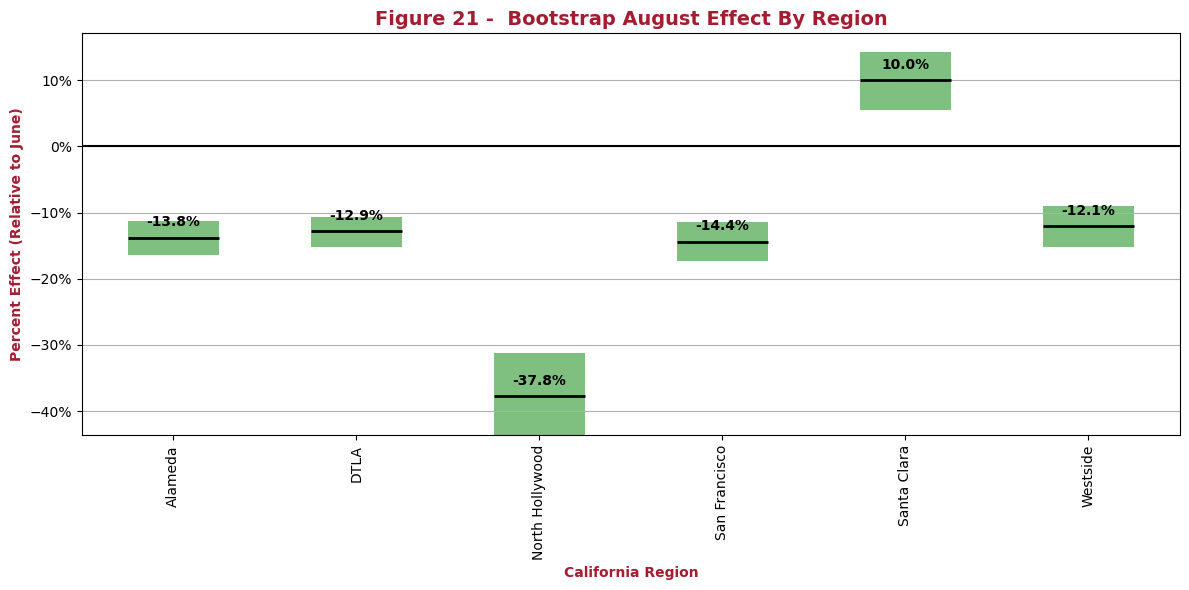

In [36]:
# Plot effects for August across all regions
plot_df = bs_effects_ci_df[(bs_effects_ci_df['effect_name'] == 'month_8')]

plot_effects_fun({'data': plot_df,
                  'x': 'start_region',
                  'bar_min': 'lci',
                  'bar_label': 'mean',
                  'bar_height': 'height',                  
                  'y_label': 'Percent Effect (Relative to June)',
                  'x_label': 'California Region',
                  'title': 'Figure 21 -  Bootstrap August Effect By Region',
                  'figsize': (12, 6)});

## Identifying Influential Points
<a id="influential"></a>

As mentioned before, the QQ plot in **Figure 15** reveals a heavy right tail driven by a number of extreme observations. The Influence plot is not available in `smf.negativebinomial` so we re-fit `smf.glm` using the model's alpha of 0.264. **Figure 22** shows the Influence Plot of the re-fitted model.

Two **CicLAvia** events, in which streets are closed to motor vehicles and opened to people on bicycles, appear in 3 out of the 4 most influential observation. The midday block in North Hollywood on [September 17, 2023][1], the morning block of the same day, and the midday block in Venice on [April 21, 2024][2]. **Figure 23** illustrates midday ridership in North Hollywood, highlighting the prominent impact an event like this can have on normal ridership patterns.

The third most influential observation in North Hollywood on the morning of June 16, 2022, was investigated, but no possible explanation was found. That Thursday morning there were 41 rides, 33 of which occurred along the four routes mapped below. No pattern or explanation is apparent, other than that three of the routes start or end at the North Hollywood MTA station, which is next to the terminus of the Orange Line, a bus route connecting Chatsworth and North Hollywood. We speculate that it could have been driven by a bus outage or traffic event, but we found no evidence to support this.

For the rest of the influential observation, some several patterns emerge. Half of the influential observations occur on Sundays. Major holidays, such as New Year’s Eve, are associated with unusually high ridership in San Francisco. **Figure 24** shows overnight ridership in San Francisco, where pronounced outliers appear around New Year’s night. In addition, 5 of the 20 most influential observations fall on a federal holiday or on the day immediately before or after one.

Seven of the 20 observations fall around October 31, November 1 or November 2, depending on the year. These dates are not federal holidays, yet they show elevated overnight ridership across several regions. [Día de los Muertos][3], is a holiday traditionally observed on November 1 and 2 (with some localities also marking October 31 or November 6) in which families and friends gather to remember loved ones who have died. [83% of California's hispanic population is of Mexican ancestry][4], which explains why these celebrations, which often include [festive costumed bike rides][5], are so popular in the state. The impact of **Día de los Muertos** on overnight ridership in San Francisco can also be observed in **Figure 23**.

These observations make it clear that bike ridership can be highly influenced by special events or celebrations, and that labeling these events in the dataset could go a long way toward improving its accuracy. Future refinements to the model could include a systematic review of local cycling events and a recoding of the holiday variable into individually labeled holidays and events, so that their effects can be estimated separately.

[1]: https://ciclavia.org/events/ciclamini-noho-2023-09/
[2]: https://ciclavia.org/events/venice-blvd-2024-04/
[3]: https://en.wikipedia.org/wiki/Day_of_the_Dead
[4]: https://latino.ucla.edu/research/15-facts-latinos-california/
[5]: https://www.sjbikeparty.org/2026/1162523543010409/

[Return to contents](#contents)

In [37]:
print(format('Negative Binomial Alpha = ' + str(format(trips_glm_nb_alpha, '.3f'))), '\n')
print(' '.join(trips_formula.split()), '\n')

hourly_glm_nb_refit = smf.glm(formula = trips_formula,
                              data = hourly_trips_df,
                              family = sm.families.NegativeBinomial(alpha = trips_glm_nb_alpha)).fit(cov_type = 'HC3')

hourly_glm_infl = hourly_glm_nb_refit.get_influence()

influential_df = hourly_trips_df.loc[hourly_glm_infl.summary_frame().sort_values(by = 'cooks_d', ascending = False).head(20).index]\
    .reset_index(drop = True)\
    .merge(bike_df[['date', 'weekday_num', 'weekend', 'holiday']].drop_duplicates(), on = 'date', how = 'left')

influential_df[['bike_year', 'date', 'month', 'weekday_num', 'weekend', 'holiday', 'hour_block', 'start_region', 'trips']]

Negative Binomial Alpha = 0.264 

trips ~ C(bike_year, Treatment(reference = 2022)) + C(month, Treatment(reference = 1)) + C(start_region, Treatment(reference = 'Alameda')) + C(hour_block, Treatment(reference = 'Midday')) 



,bike_year,date,month,weekday_num,weekend,holiday,hour_block,start_region,trips
0,2024,2023-09-17,9,6,1,0,Midday,North Hollywood,99
1,2022,2022-06-16,6,3,0,0,Morning,North Hollywood,41
2,2024,2023-09-17,9,6,1,0,Morning,North Hollywood,47
3,2024,2024-04-21,4,6,1,0,Midday,Westside,802
4,2026,2025-11-01,11,5,1,0,Overnight,San Francisco,1801
5,2023,2023-01-01,1,6,1,1,Overnight,San Francisco,780
6,2024,2024-01-01,1,0,0,1,Overnight,San Francisco,1020
7,2025,2025-01-01,1,2,0,1,Overnight,San Francisco,1185
8,2026,2025-11-01,11,5,1,0,Overnight,Santa Clara,79
9,2022,2021-08-28,8,5,1,0,Overnight,Santa Clara,48


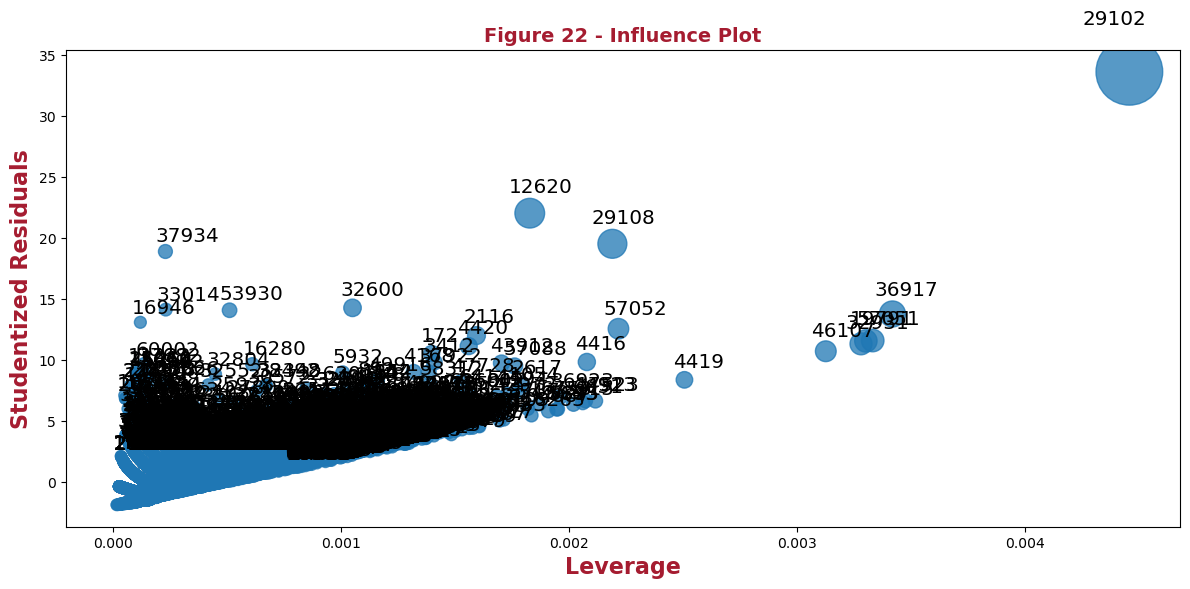

In [38]:
fig, ax = plt.subplots(figsize = (12, 6))
hourly_glm_infl.plot_influence(ax = ax)
ax.set_title('Figure 22 - Influence Plot', title_large_font_dict)
ax.set_xlabel('Leverage', axis_font_dict)
ax.set_ylabel('Studentized Residuals', axis_font_dict)
plt.tight_layout()
plt.show()

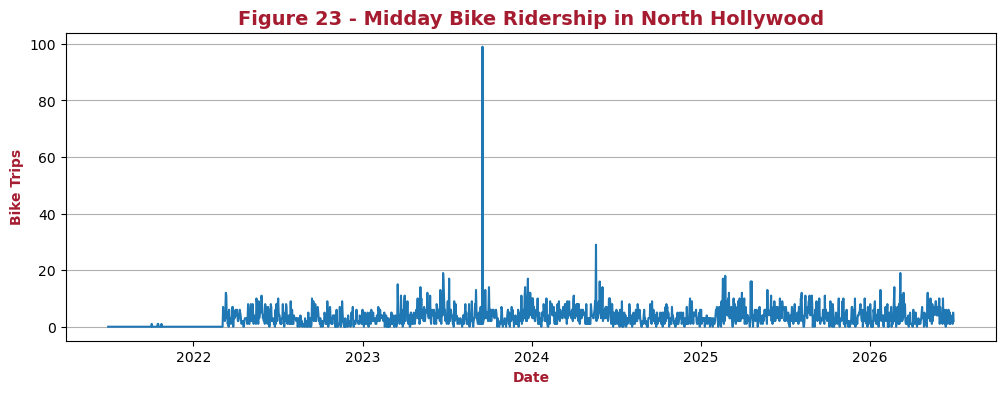

In [39]:
plot_df = hourly_trips_df.query('start_region == "North Hollywood" & hour_block == "Midday"')

fig, ax = plt.subplots(figsize = (12, 4))
ax.set_title('Figure 23 - Midday Bike Ridership in North Hollywood', fontdict = title_large_font_dict)
ax.plot(plot_df['date'], plot_df['trips'])
ax.set_ylabel('Bike Trips', fontdict = axis_font_dict)
ax.set_xlabel('Date', fontdict = axis_font_dict)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, pos: f'{y:,.0f}'))
plt.grid(axis = 'y')
plt.show()

In [40]:
noho_outlier_df = bike_df[bike_df['date'] == '2022-06-16']\
    .query('start_region == "North Hollywood" & hour_block == "Morning"')\
    .groupby(['trip_route_category', 'user_type', 'start_lat', 'start_lon', 'end_lat', 'end_lon'], as_index = False)\
    .agg(trip_distance = ('trip_distance', 'mean'),
         trips = ('trip', 'sum'))\
    .sort_values(by = 'trips', ascending = False)\
    .query('trips > 2')\
    .assign(plot_region = 'the morning of June 16, 2022 in North Hollywood')

noho_outlier_df.drop(['plot_region'], axis = 1)

,trip_route_category,user_type,start_lat,start_lon,end_lat,end_lon,trip_distance,trips
2,One Way,Casual,34.165218,-118.355148,34.168751,-118.361870,0.455261,9
4,One Way,Casual,34.168751,-118.361870,34.168629,-118.377068,0.868864,9
9,Round Trip,Casual,34.168629,-118.377068,34.168629,-118.377068,NaN,8
3,One Way,Casual,34.168629,-118.377068,34.165218,-118.355148,1.275096,7


In [41]:
station_to_station_plot_fun(noho_outlier_df, num_cols = 4, num_rows = 1, w = 1100, h = 300, z = 13)

Top 4 Station-to-Station Routes in the morning of June 16, 2022 in North Hollywood



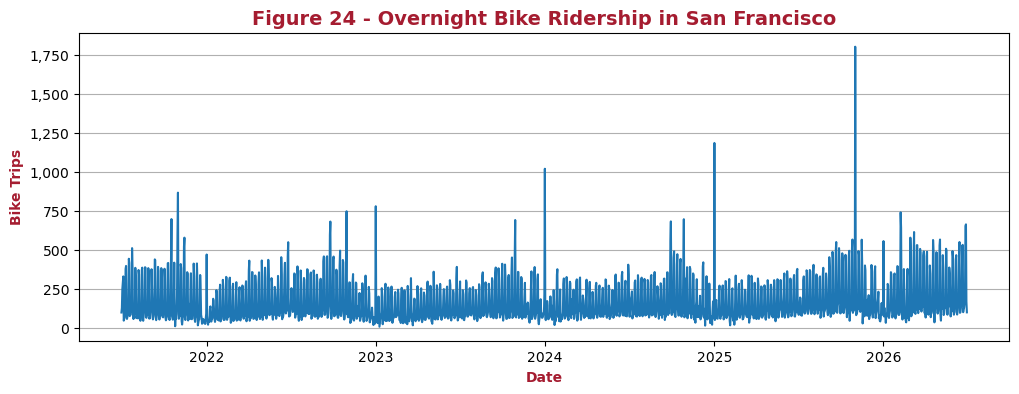

In [42]:
plot_df = hourly_trips_df.query('start_region == "San Francisco" & hour_block == "Overnight"')

fig, ax = plt.subplots(figsize = (12, 4))
ax.set_title('Figure 24 - Overnight Bike Ridership in San Francisco', fontdict = title_large_font_dict)
ax.plot(plot_df['date'], plot_df['trips'])
ax.set_ylabel('Bike Trips', fontdict = axis_font_dict)
ax.set_xlabel('Date', fontdict = axis_font_dict)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, pos: f'{y:,.0f}'))
plt.grid(axis = 'y')
plt.show()

# Part 2 - Modeling Trip Duration
<a id="duration"></a>

As shown in **Figure 5**, trip duration is strongly right-skewed. We therefore applied a log transformation, which brings the distribution closer to normality, and proceed to model log duration with ordinary least squares (OLS). To reduce computation time, we fitted the model to a stratified sample of 1,791,251 trips. Given the size of the sample, the estimated coefficients should be very close to those obtained from the full dataset of approximately 18 million trips.

Trip speed was excluded as a predictor for duration since it is not measured directly but derived from distance and duration, so including it would introduce data leakage.

To explore the correct interpretation for interaction parameters, a two-way interaction term between **start region** and **trip route category** was specified and incorporated into the model. This formulation permits the effect of trip route category to vary across start regions (and, symmetrically, the effect of start region to vary across route categories), thereby allowing the interaction coefficients to be examined not as isolated estimates but in relation to their respective main effects and reference levels.

[Return to contents](#contents)

In [43]:
if use_raw_data:
    # Sample data
    sample_groups = ['start_region', 'trip_route_category', 'bike_type', 'user_type', 'bike_year', 'month', 'weekday_num', 'hour']
    duration_sample_df = bike_df.groupby(sample_groups, group_keys = False).apply(lambda x: x.sample(frac = 0.1, random_state = 50))
    duration_sample_df = pd.concat([duration_sample_df, bike_df.loc[duration_sample_df.index][sample_groups]], axis = 1)
    
    reproducibility = {105: 'FEB02CCD18379DFD', 580: '7AA774258E301F70', 934: 'E49A923821D5B867'}
    if sum([duration_sample_df.iloc[k]['trip_id'] == v for k, v in reproducibility.items()]) == len(reproducibility):
        print('Reproducibility check OK. Sample dataset of ' + format(duration_sample_df.shape[0], ',.0f') + ' rows.')
        print(format(duration_sample_df.shape[0] / bike_df.shape[0], '.2%'))
    else:
        print('Will not produce reproducible results.')
else:
    duration_sample_df = bike_df.copy()

Reproducibility check OK. Sample dataset of 1,791,251 rows.
9.87%


## Duration OLS Model
<a id="duration_model"></a>

The model explains 11.8% of the variation in log trip duration. The adjusted R² is identical, so the 50 predictors are not inflating the fit. This is too small to predict individual trips, which are likely driven largely by factors not observed in the data, such as trip purpose, the specific route taken, and whether the rider stopped along the way. The residuals, shown in **Figure 25**, are roughly symmetric and bell-shaped (skew 0.14, kurtosis 3.11). The QQ plot shows lighter tails than a normal distribution, and the sharp diagonal edges in the residuals-vs-predicted plot suggest trip durations are bounded by minimum and maximum cutoffs. With 1.79 million trips, the formal normality tests reject even trivial departures, so the visual checks are more informative than their p-values.

Most coefficients are statistically significant, and the model as a whole explains duration significantly better than an intercept-only model (F = 4,816, p < 0.001). At this sample size nearly any nonzero effect is significant, so effect size matters more than significance. Because the outcome is on a log scale, a coefficient b corresponds to a (eᵇ − 1) × 100% change in typical trip duration, holding the other variables constant.

[Return to contents](#contents)

                            OLS Regression Results                            
Dep. Variable:       duration_min_log   R-squared:                       0.118
Model:                            OLS   Adj. R-squared:                  0.118
Method:                 Least Squares   F-statistic:                     4816.
Date:                Thu, 19 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:16:02   Log-Likelihood:            -1.7612e+06
No. Observations:             1791251   AIC:                         3.522e+06
Df Residuals:                 1791200   BIC:                         3.523e+06
Df Model:                          50                                         
Covariance Type:            nonrobust                                         
                                                                                                                                              coef    std err          t      P>|t|      [0.025      0.975]
------

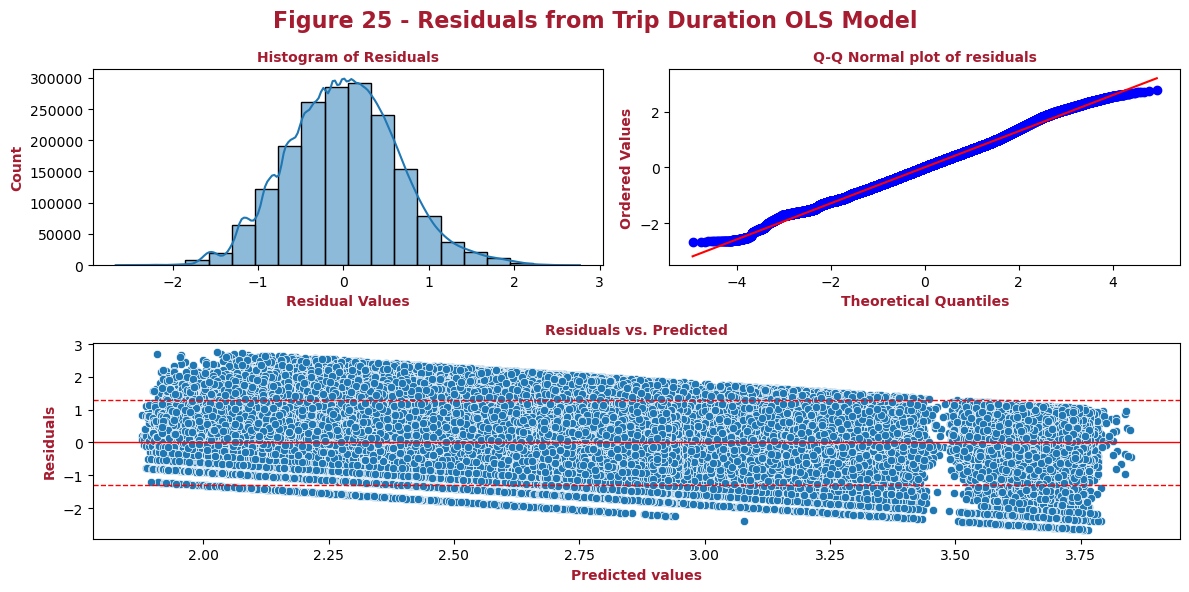

In [44]:
duration_formula = "duration_min_log ~ C(user_type, Treatment(reference = 'Casual'))\
    + C(start_region, Treatment(reference = 'Alameda')) * C(trip_route_category, Treatment(reference = 'One Way'))\
    + C(bike_type, Treatment(reference = 'Electric'))\
    + C(bike_year, Treatment(reference = 2022))\
    + C(quarter, Treatment(reference = 1))\
    + C(weekday_num, Treatment(reference = 0))\
    + C(hour, Treatment(reference = 12))\
    + C(holiday, Treatment(reference = 0))"
duration_ols = smf.ols(formula = duration_formula, 
                       data = duration_sample_df).fit()
print(duration_ols.summary())

plot_resid_fun({'prediction': duration_ols.predict(duration_sample_df),
                'residuals': duration_ols.resid,
                'title': 'Figure 25 - Residuals from Trip Duration OLS Model',
                'figsize': (12, 6)});

## Duration Main Effects Plus Interactions
<a id="duration_effects"></a>

The intercept implies a baseline duration of about 12 minutes.

**Regional differences**. The reference trip is a one-way trip starting in Alameda County. Relative to it, trips starting in Southern California **regions** were substantially longer: Westside by 95%, Downtown Los Angeles (DTLA) by 43%, and North Hollywood by 43%. The North Hollywood estimate was less precise (95% CI: 26% to 61%). Differences within Northern California were much smaller: trips starting in San Francisco were 17% longer than in Alameda, and trips starting in Santa Clara were not statistically different that those in Alameda county.

**User type**. **Member** trips were approximately 28% shorter than those of casual riders, which is consistent with the hypothesis that casual riders take longer, leisure-oriented trips.

**Calendar effects**. Trips on **federal holidays** were approximately 8% longer than on other days. **Saturday** and **Sunday** trips were approximately 12% and 11% longer, respectively, than Monday trips.

**Time of day**. As shown in **Figure 26**, trips between 1pm and 5:59pm were 3% to 6% longer than trips at the 12pm reference **hour**. Trips between 11pm and 6:59am were 12% to 18% shorter than trips at noon and their their confidence intervals were much wider due to lower trip frequency.

**Bike type**. In the earlier models tested, **bike type** was not statistically significant. In this final model, it reaches statistical significance, but the effect is negligible in size (−0.8% for standard relative to electric bicycles).

**Round trips**. The round-trip effect varied by region. Round trips were substantially longer than one-way trips in Alameda (118%), the Westside (63%), DTLA (61%) and Santa Clara (33%), but barely longer in San Francisco (2%). The interaction for North Hollywood was not statistically significant, so its round-trip effect is indistinguishable from that of the reference region. Possible explanations include differences in station density or in the type of riding done in each region. 


[Return to contents](#contents)

In [45]:
# Model Coefficients and Effects
ols_duration_coeff_df = model_coeff_fun(duration_ols)
ols_duration_effects_df = model_coeff_fun(duration_ols, log = True)
ols_duration_effects_df['color'] = ['green' if c else 'red' for c in ols_duration_effects_df['sign']]
ols_duration_effects_df['height'] = ols_duration_effects_df['effect_975'] - ols_duration_effects_df['effect_025']

# Intercept
duration_intercept = ols_duration_coeff_df[ols_duration_coeff_df['coef_name'] == 'Intercept']['coef'].iloc[0]
ols_avg_duration = np.exp(duration_intercept)
print('Average Model Duration: ' + str(format(ols_avg_duration, '.1f')) + ' minutes\n')

# Model Effects
ols_duration_effects_df.drop(['color', 'height'], axis = 1)

Average Model Duration: 11.5 minutes



,effect_name,effect_ref,inter_name,inter_ref,p_value,sign,effect,effect_025,effect_975
0,user_type_Member,Casual,None,None,0.000,True,-0.280357,-0.281795,-0.278916
1,start_region_DTLA,Alameda,None,None,0.000,True,0.426894,0.419068,0.434763
2,start_region_North Hollywood,Alameda,None,None,0.000,True,0.426181,0.264909,0.608014
3,start_region_San Francisco,Alameda,None,None,0.000,True,0.171635,0.166491,0.175860
4,start_region_Santa Clara,Alameda,None,None,0.296,False,0.004309,-0.003992,0.012072
5,start_region_Westside,Alameda,None,None,0.000,True,0.952089,0.938666,0.965998
6,trip_route_category_Round Trip,One Way,None,None,0.000,True,1.179946,1.127612,1.234461
7,bike_type_Standard,Electric,None,None,0.000,True,-0.008067,-0.009950,-0.005982
8,bike_year_2023,2022,None,None,0.000,True,-0.021564,-0.024690,-0.017839
9,bike_year_2024,2022,None,None,0.000,True,-0.033815,-0.037287,-0.030524


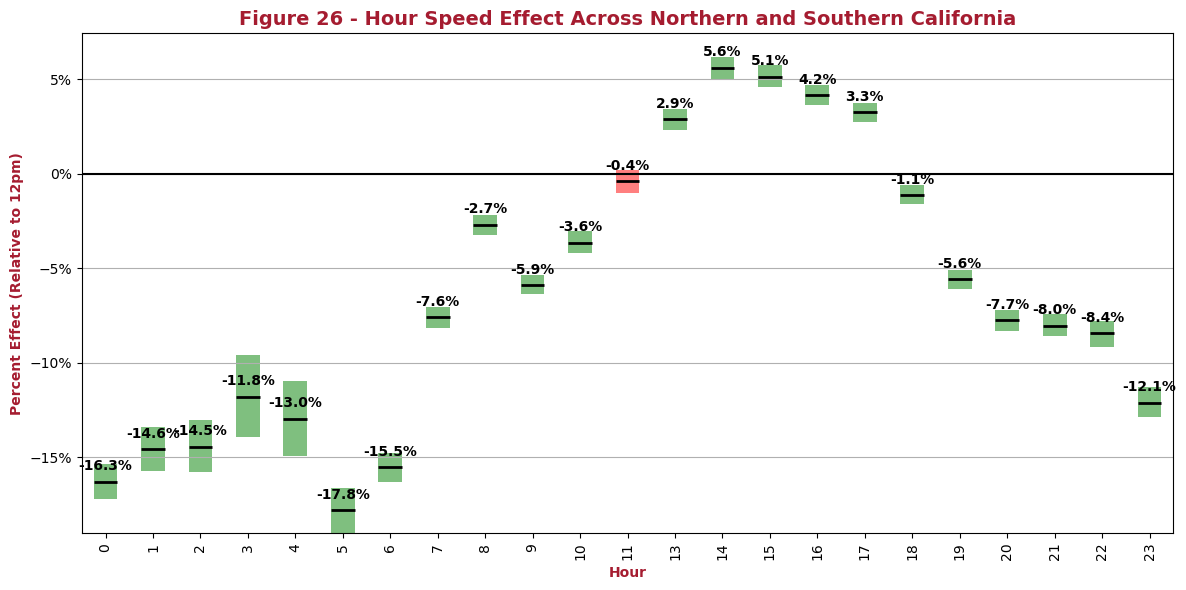

In [46]:
# Hour Effects
plot_df = ols_duration_effects_df[ols_duration_effects_df['effect_name'].str.contains('hour')]
plot_df['effect_name'] = plot_df['effect_name'].str.replace('hour_', '')

plot_effects_fun({'data': plot_df,
                  'x': 'effect_name',
                  'bar_min': 'effect_025',
                  'bar_label': 'effect',
                  'bar_height': 'height',                  
                  'y_label': 'Percent Effect (Relative to 12pm)',
                  'x_label': 'Hour',
                  'title': 'Figure 26 - Hour Speed Effect Across Northern and Southern California',
                  'figsize': (12, 6)});

In [47]:
# Round trip effects across regions (main effect + interaction)

# Interaction Coeff
rt_region_inter_df = ols_duration_coeff_df[ols_duration_coeff_df['inter_name'].str.contains('trip_route_category')]\
    [['coef_name', 'p_value', 'sign', 'coef']]\
    .rename(columns = {'coef_name': 'start_region', 
                       'p_value': 'region_rt_p', 
                       'coef': 'region_rt_coef'})\
    .reset_index(drop = True)
rt_region_inter_df['start_region'] = rt_region_inter_df['start_region'].str.replace('start_region_', '')

# RT Coeff
rt_coeff_df = bike_df[['start_region']]\
    .drop_duplicates()\
    .reset_index(drop = True)\
    .merge(ols_duration_coeff_df[ols_duration_coeff_df['coef_name'] == 'trip_route_category_Round Trip'][['coef', 'p_value']], 
           how = 'cross')\
    .rename(columns = {'p_value': 'rt_p', 
                       'coef': 'rt_coef'})

# Combine Main Coefficient and Interaction and calculate Effect
rt_effect_df = rt_coeff_df.merge(rt_region_inter_df, on = ['start_region'], how = 'left')
rt_effect_df['region_rt_coef'] = rt_effect_df['region_rt_coef'].fillna(0)
rt_effect_df['rt_effect'] = np.exp(rt_effect_df['rt_coef'].astype(float) + 
                                   rt_effect_df['region_rt_coef'].astype(float)) - 1
rt_effect_df = rt_effect_df[['start_region', 'rt_coef', 'rt_p', 'region_rt_coef', 'region_rt_p', 'rt_effect']]\
    .sort_values(by = 'rt_effect', ascending = False)\
    .reset_index(drop = True)
rt_effect_df['rt_effect'] = [format(e, '.0%') for e in rt_effect_df['rt_effect']]

rt_effect_df

,start_region,rt_coef,rt_p,region_rt_coef,region_rt_p,rt_effect
0,Alameda,0.7793,0.000,0.0000,NaN,118%
1,North Hollywood,0.7793,0.000,-0.0278,0.809,112%
2,Westside,0.7793,0.000,-0.2888,0.000,63%
3,DTLA,0.7793,0.000,-0.3018,0.000,61%
4,Santa Clara,0.7793,0.000,-0.4921,0.000,33%
5,San Francisco,0.7793,0.000,-0.7558,0.000,2%


# Part 3 - Modeling Trip Distance
<a id="distance"></a>

As shown in **Figure 10**, trip distance is strongly right-skewed. We therefore applied a log transformation, which brings the distribution closer to normality, and proceed to model log duration with ordinary least squares (OLS). To reduce computation time, we fitted the model to a stratified sample of 1,480,561 **one-way** trips. Given the size of the sample, the estimated coefficients should be very close to those obtained from the full dataset of approximately 18 million trips.

[Return to contents](#contents)

In [48]:
bike_oneway_df = bike_df[bike_df['trip_route_category'] == 'One Way'].reset_index(drop = True)

In [49]:
if use_raw_data:
    # Sample data
    sample_groups = ['start_region', 'bike_type', 'user_type', 'bike_year', 'month', 'weekday_num', 'hour']
    distance_sample_df = bike_oneway_df.groupby(sample_groups, group_keys = False).apply(lambda x: x.sample(frac = 0.1, random_state = 23))
    distance_sample_df = pd.concat([distance_sample_df, bike_oneway_df.loc[distance_sample_df.index][sample_groups]], axis = 1)
    
    reproducibility = {195: 'CDC912452A556AD9', 384: 'AA0C4D378C890666', 831: '4BD31F0FD0C27ADA'}
    if sum([distance_sample_df.iloc[k]['trip_id'] == v for k, v in reproducibility.items()]) == len(reproducibility):
        print('Reproducibility check OK. Sample dataset of ' + format(distance_sample_df.shape[0], ',.0f') + ' rows.')
        print(format(distance_sample_df.shape[0] / bike_df.shape[0], '.2%'))
    else:
        print('Will not produce reproducible results.')
else:
    distance_sample_df = bike_oneway_df.copy()

Reproducibility check OK. Sample dataset of 1,480,561 rows.
8.16%


## Distance OLS Model

<a id="distance_model"></a>

The model explains 7.3% of the variation in log trip distance, and its adjusted R² is identical, so the 52 predictors are not inflating the fit. This is low, and it means the model captures average differences between groups of trips rather than predicting any individual trip. Trip distance is likely driven mainly by factors not in the data, such as the rider’s destination and trip purpose. The model as a whole fits significantly better than an intercept-only model (F = 2,240, p < 0.001). With nearly 1.5 million trips, almost any nonzero effect is statistically significant, so effect size matters more than significance.

The residuals, shown in **Figure 27**, are right-skewed (skew 0.50). The QQ plot shows a floor on the low end and a heavy upper tail, and the residuals-vs-predicted plot shows a sharp lower boundary, so some very long trips are far longer than the model predicts. The spread is also wide relative to the narrow range of predictions (about 0.4 to 1.0 on the log scale). Because the outcome is on a log scale, a coefficient b corresponds to a (eᵇ − 1) × 100% change in typical distance, holding the other variables constant.

[Return to contents](#contents)

                            OLS Regression Results                            
Dep. Variable:      trip_distance_log   R-squared:                       0.073
Model:                            OLS   Adj. R-squared:                  0.073
Method:                 Least Squares   F-statistic:                     2240.
Date:                Thu, 19 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:17:49   Log-Likelihood:            -4.7636e+05
No. Observations:             1480561   AIC:                         9.528e+05
Df Residuals:                 1480508   BIC:                         9.535e+05
Df Model:                          52                                         
Covariance Type:            nonrobust                                         
                                                                               coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------

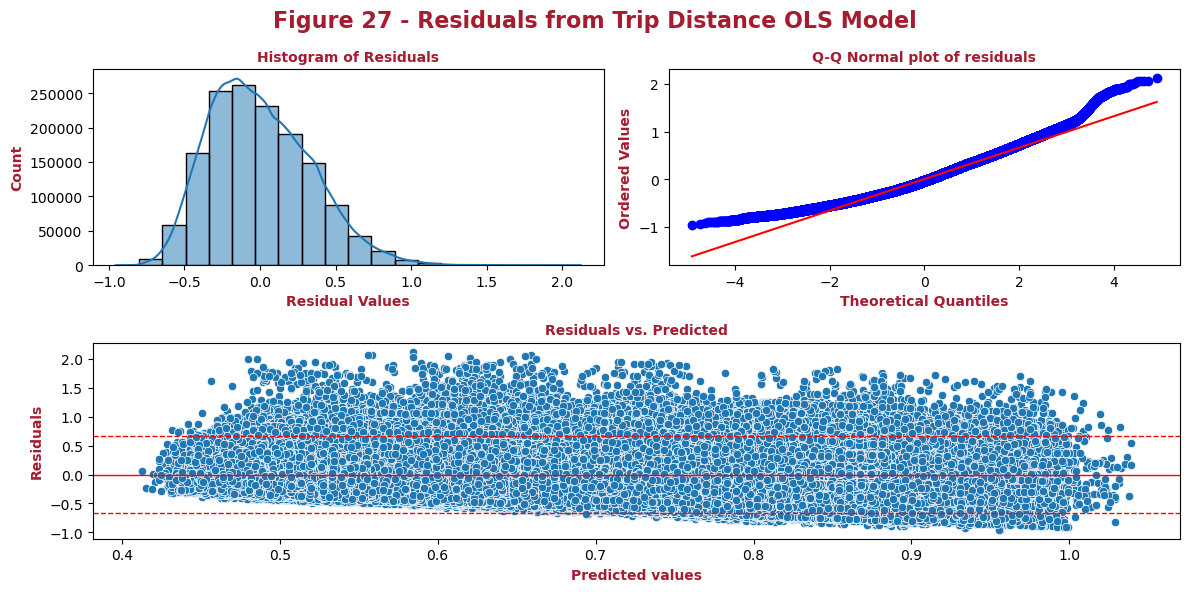

In [50]:
distance_formula = "trip_distance_log ~ C(bike_type, Treatment(reference = 'Electric'))\
    + C(start_region, Treatment (reference = 'San Francisco'))\
    + C(user_type, Treatment(reference = 'Casual'))\
    + C(hour, Treatment(reference = 12))\
    + C(weekday_num, Treatment(reference = 0))\
    + C(bike_year, Treatment(reference = 2022))\
    + C(month, Treatment(reference = 1))\
    + C(holiday, Treatment(reference = 0))"

distance_ols = smf.ols(formula = distance_formula, 
                       data = distance_sample_df).fit()

print(distance_ols.summary())

plot_resid_fun({'prediction': distance_ols.predict(distance_sample_df),
                'residuals': distance_ols.resid,
                'title': 'Figure 27 - Residuals from Trip Distance OLS Model',
                'figsize': (12, 6)});

## Distance Effects

<a id="distance_effects"></a>

The intercept implies a baseline distance of about 2.3 miles.

Trip distance, shown in **Figure 28**, follows a similar seasonal pattern. Distances in February and November are not statistically distinguishable from those in January, while distances in December are significantly lower. The July decline observed in **Figure 2** is also present here. These results suggest that weather influences not only the number of trips taken but also their length, with warmer months producing longer trips than January.

An initial hypothesis of this study was that the relative density of San Francisco, compared with the rest of the state, would produce shorter trips there. The results in **Figure 29** do not support this. With the exception of the Westside of Los Angeles, where trips are 9.4% longer, trips in all other regions are between 7% and 16% shorter than those in the City and County of San Francisco.

Trip distance also varies by bicycle type and rider type. Standard bikes are associated with trips 11.5% shorter than those on **electric bikes**, and **members** take trips 8% shorter than casual users. Trips taken on **holidays** are approximately 1% longer than those on non-holidays.

**Figure 30** presents the combined (significant) effects of departure hour on trip distance and duration, relative to a 12pm baseline. The plane is partitioned into four quadrants, each describing a distinct trip profile:
1. **Upper right (longer and farther)**. Trips in this quadrant exhibit both greater duration and greater distance than those departing at 1pm. These are predominantly trips beginning in the afternoon, between 12pm and 6pm and may reflect commutes away from work.
2. **Lower left (shorter and closer)**. Trips in this quadrant are of shorter duration and cover less distance than the baseline. They are primarily evening and overnight departures, which may reflect local exploration followed by a return to a point near the origin.
3. **Upper left (farther but faster)**. Trips in this quadrant cover greater distances in less time than the baseline. They are chiefly early-morning departures. Trips beginning at 6pm also fall within this quadrant, which may be interpreted as a transitional period between the afternoon pattern (upper right) and the evening and overnight pattern (lower left).
4. **Lower right (longer but closer)**. Trips in this quadrant would be characterized by extended duration with limited distance, consistent with lingering in the vicinity of the origin. No hours were observed in this quadrant.

**Holiday** trips are longer in both duration and distance than non-holiday trips. This pattern is consistent with more leisurely, recreational use on days when riders are free from work or school commitments, and it contrasts with the shorter, more utilitarian trips that typically characterize weekday travel. **Members**, by contrast, take quicker trips and stay closer to their origin. This may reflect purposeful, routine travel, such as short commutes or errands between familiar locations, whereas casual users appear more inclined toward extended or exploratory rides. Together, these findings suggest that rider type and calendar context shape not only when people ride but also how far and how long they ride.

[Return to contents](#contents)

In [51]:
# Model Coefficients and Effects
ols_distance_coeff_df = model_coeff_fun(distance_ols)
ols_distance_effects_df = model_coeff_fun(distance_ols, log = True)
ols_distance_effects_df['color'] = ['green' if c else 'red' for c in ols_distance_effects_df['sign']]
ols_distance_effects_df['height'] = ols_distance_effects_df['effect_975'] - ols_distance_effects_df['effect_025']

# Intercept
distance_intercept = ols_distance_coeff_df[ols_distance_coeff_df['coef_name'] == 'Intercept']['coef'].iloc[0]
ols_avg_distance = np.exp(distance_intercept)
print('Average Model Distance: ' + str(format(ols_avg_distance, '.1f')) + ' miles\n')

ols_distance_effects_df.drop(['color', 'height'], axis = 1)

Average Model Distance: 2.3 miles



,effect_name,effect_ref,p_value,sign,effect,effect_025,effect_975
0,bike_type_Standard,Electric,0.000,True,-0.114763,-0.115736,-0.113966
1,start_region_Alameda,San Francisco,0.000,True,-0.073740,-0.075960,-0.072257
2,start_region_DTLA,San Francisco,0.000,True,-0.133159,-0.134978,-0.131511
3,start_region_North Hollywood,San Francisco,0.001,True,-0.098414,-0.152106,-0.041130
4,start_region_Santa Clara,San Francisco,0.000,True,-0.159199,-0.162220,-0.156335
5,start_region_Westside,San Francisco,0.000,True,0.093846,0.090897,0.097462
6,user_type_Member,Casual,0.000,True,-0.081580,-0.082406,-0.080569
7,hour_0,12,0.000,True,-0.036902,-0.043046,-0.030524
8,hour_1,12,0.000,True,-0.030040,-0.037287,-0.022738
9,hour_2,12,0.000,True,-0.026833,-0.036324,-0.016856


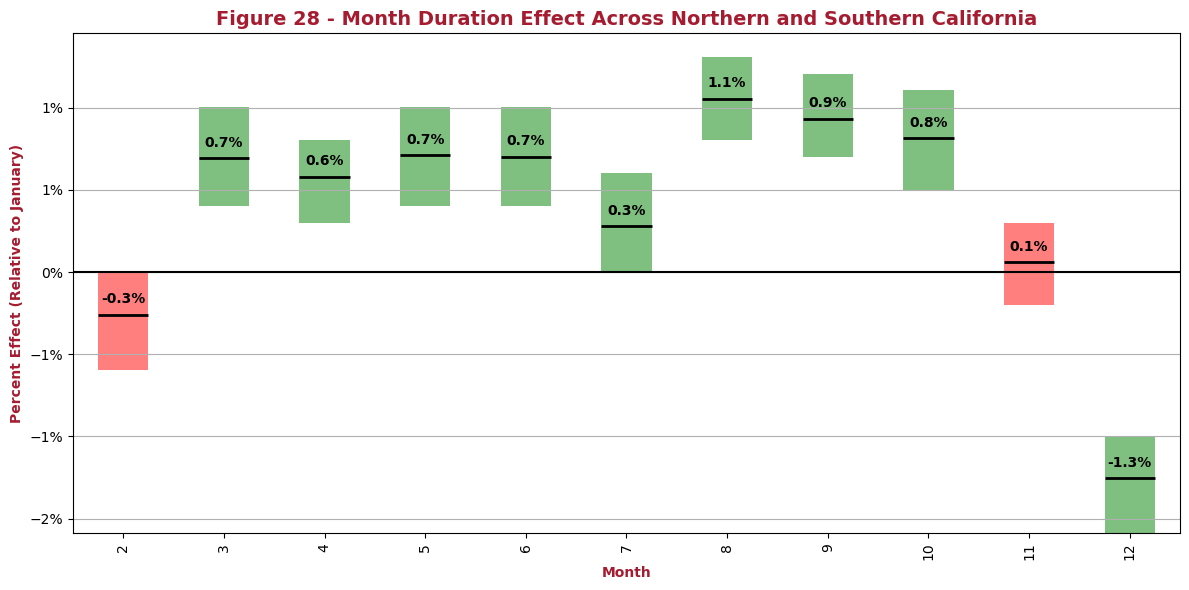

In [52]:
plot_df = ols_distance_effects_df[ols_distance_effects_df['effect_name'].str.contains('month')]
plot_df['effect_name'] = plot_df['effect_name'].str.replace('month_', '')

plot_effects_fun({'data': plot_df,
                  'x': 'effect_name',
                  'bar_min': 'effect_025',
                  'bar_label': 'effect',
                  'bar_height': 'height',                  
                  'y_label': 'Percent Effect (Relative to January)',
                  'x_label': 'Month',
                  'title': 'Figure 28 - Month Duration Effect Across Northern and Southern California',
                  'figsize': (12, 6)});

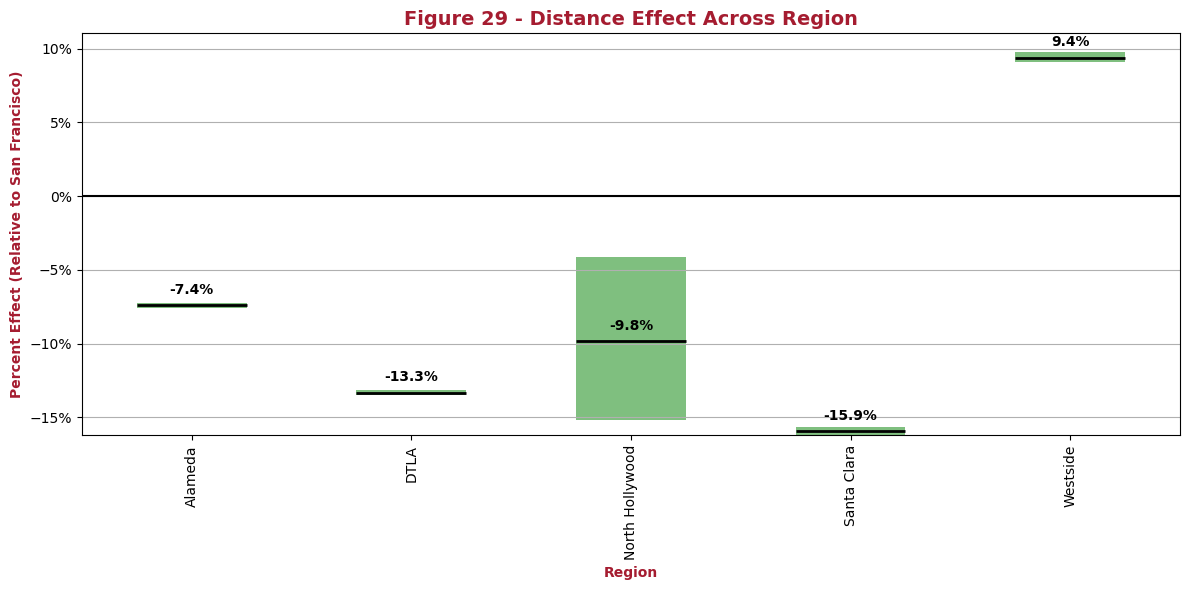

In [53]:
plot_df = ols_distance_effects_df[ols_distance_effects_df['effect_name'].str.contains('start_region')]
plot_df['effect_name'] = plot_df['effect_name'].str.replace('start_region_', '')

plot_effects_fun({'data': plot_df,
                  'x': 'effect_name',
                  'bar_min': 'effect_025',
                  'bar_label': 'effect',
                  'bar_height': 'height',                  
                  'y_label': 'Percent Effect (Relative to San Francisco)',
                  'x_label': 'Region',
                  'title': 'Figure 29 - Distance Effect Across Region',
                  'figsize': (12, 6)});

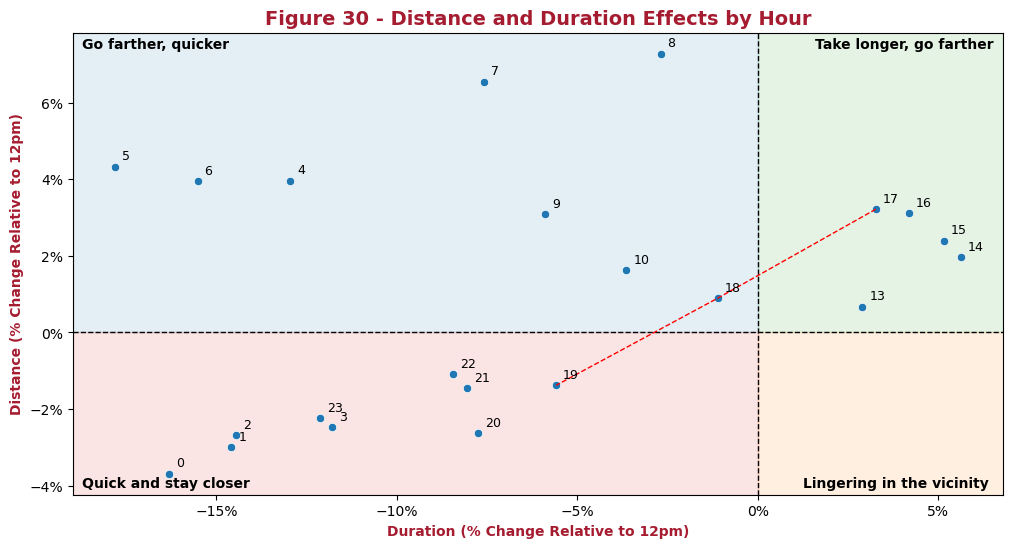

In [54]:
# Combine all significant effects from both distance and duration models
dur_dist_effects_df = pd.concat([ols_duration_effects_df.assign(model = 'duration'), 
                                 ols_distance_effects_df.assign(model = 'distance')])\
    [['effect_name', 'effect_ref', 'inter_name', 'inter_ref', 'sign', 'model', 'effect']]
dur_dist_effects_df = dur_dist_effects_df[dur_dist_effects_df['sign']]
dur_dist_effects_df['inter_name'] = dur_dist_effects_df['inter_name'].fillna('None')
dur_dist_effects_df['inter_ref'] = dur_dist_effects_df['inter_ref'].fillna('None')
dur_dist_effects_df = dur_dist_effects_df.pivot(index = ['effect_name', 'effect_ref', 'inter_name', 'inter_ref'], 
                                                columns = 'model', 
                                                values = 'effect')\
    .reset_index()\
    .dropna()
dur_dist_effects_df.loc[(dur_dist_effects_df['distance'] > 0) & 
    (dur_dist_effects_df['duration'] > 0), 'label'] = 'Take longer, go farther'
dur_dist_effects_df.loc[(dur_dist_effects_df['distance'] > 0) & 
    (dur_dist_effects_df['duration'] < 0), 'label'] = 'Go farther, quicker'
dur_dist_effects_df.loc[(dur_dist_effects_df['distance'] < 0) & 
    (dur_dist_effects_df['duration'] > 0), 'label'] = 'Lingering in the vicinity'
dur_dist_effects_df.loc[(dur_dist_effects_df['distance'] < 0) & 
    (dur_dist_effects_df['duration'] < 0), 'label'] = 'Quick and stay closer'

# Plot Combined Hour Effects
plot_dist_dur_fun({'data': dur_dist_effects_df,
                   'effect': 'hour',
                   'connect_plot': ['17', '18', '19'],
                   'y_label': 'Distance (% Change Relative to 12pm)',
                   'x_label': 'Duration (% Change Relative to 12pm)',
                   'title': 'Figure 30 - Distance and Duration Effects by Hour',
                   'figsize': (12, 6)});

In [55]:
dur_dist_effects_df

model,effect_name,effect_ref,inter_name,inter_ref,distance,duration,label
0,bike_type_Standard,Electric,None,None,-0.114763,-0.008067,Quick and stay closer
1,bike_year_2023,2022,None,None,-0.006678,-0.021564,Quick and stay closer
2,bike_year_2024,2022,None,None,-0.010346,-0.033815,Quick and stay closer
3,bike_year_2025,2022,None,None,-0.002796,-0.032461,Quick and stay closer
4,bike_year_2026,2022,None,None,0.003807,-0.022542,"Go farther, quicker"
5,holiday_1,0,None,None,0.009848,0.082854,"Take longer, go farther"
6,hour_0,12,None,None,-0.036902,-0.163058,Quick and stay closer
7,hour_1,12,None,None,-0.030040,-0.145894,Quick and stay closer
8,hour_10,12,None,None,0.016230,-0.036420,"Go farther, quicker"
10,hour_13,12,None,None,0.006722,0.029013,"Take longer, go farther"


# Part 4 - Modeling Trip Speed
<a id="speed"></a>

As previously noted, trip speed is not directly recorded; rather, it is estimated using trip duration and the linear Euclidean distance between origin and destination stations. Consequently, trips in which users checked out a bicycle without riding continuously for the entire rental period yield artificially low speed estimates. For instance, Trip 165260272, in which a user covered just over half a mile over a 57-minute duration, produces an estimated speed of only 0.6 mph, suggesting that a substantial portion of the trip was spent idle. To account for this anomaly and to try to isolate continuous, uninterrupted travel, the speed inference models are restricted to trips with estimated speeds between 5 mph and 16.5 mph. The lower limit was selected to be just faster than the [average walking pace of 3 mph][1]. The upper limit was selected based on an visual inspection of **Figure 12** and a 10% increase in speed from the author's average **15 mph** pace during an uninterrupted 5-mile training session. **Figure 31** shows the distribution excluding these outliers.

To reduce computation time, we fitted the model to a stratified sample of 1,161,539 **one-way** trips. Given the size of the sample, the estimated coefficients should be very close to those obtained from the full dataset of approximately 18 million trips.

[1]: https://www.healthline.com/health/exercise-fitness/average-walking-speed#average-speed-by-sex
[Return to contents](#contents)

In [56]:
bike_df[bike_df['trip_id'] == '165260272'][['cal_region', 'trip_route_category', 'bike_type', 'user_type', 'duration_min',
                                            'start_station_id', 'end_station_id', 'trip_distance', 'trip_speed']]

,cal_region,trip_route_category,bike_type,user_type,duration_min,start_station_id,end_station_id,trip_distance,trip_speed
29,SoCal,One Way,Electric,Member,57,4580,4583,0.632988,0.666303


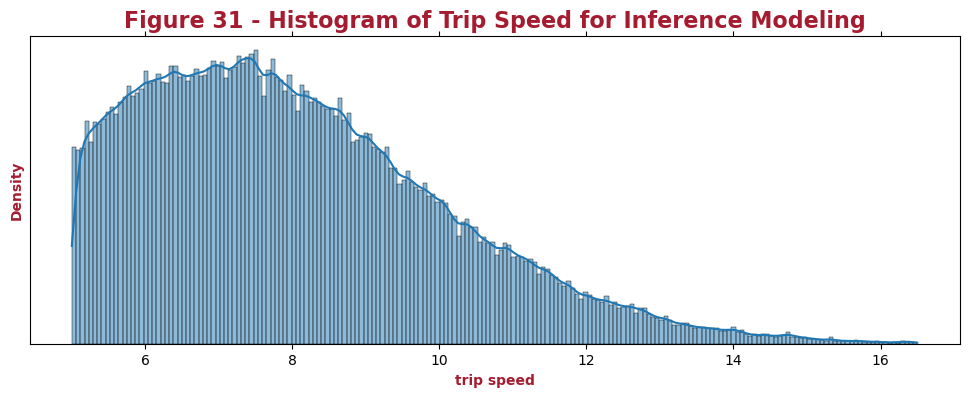

In [57]:
# Remove outliers for inference
speed_df = bike_df.query('trip_route_category == "One Way" & trip_speed >= 5 & trip_speed <= 16.5')

eda_hist_fun({'data': speed_df,
              'column': 'trip_speed',
              'title': 'Figure 31 - Histogram of Trip Speed for Inference Modeling',
              'format': ',.0f',
              'figsize': (12, 4),
              'bin_num': 200});

In [58]:
if use_raw_data:
    # Sample data
    sample_groups = ['start_region', 'bike_type', 'user_type', 'bike_year', 'month', 'weekday_num', 'hour']
    speed_sample_df = speed_df.groupby(sample_groups, group_keys = False).apply(lambda x: x.sample(frac = 0.1, random_state = 961))
    speed_sample_df = pd.concat([speed_sample_df, speed_df.loc[speed_sample_df.index][sample_groups]], axis = 1)
    
    reproducibility = {153: '935514A661234693', 769: '89B688B31A8B55D4', 948: '4C1AFFDA5D1C8E7D'}
    if sum([speed_sample_df.iloc[k]['trip_id'] == v for k, v in reproducibility.items()]) == len(reproducibility):
        print('Reproducibility check OK. Sample dataset of ' + format(speed_sample_df.shape[0], ',.0f') + ' rows.')
        print(format(speed_sample_df.shape[0] / speed_df.shape[0], '.2%'))
    else:
        print('Will not produce reproducible results.')
else:
    speed_sample_df = speed_df.copy()

Reproducibility check OK. Sample dataset of 1,161,539 rows.
9.91%


## Speed GLM Model (Gamma)

<a id="speed_model"></a>

A Gamma generalized linear model with a log link was fitted to trip speed (1,161,539 trips, 14 categorical predictors). The Gamma family suits a positive, right-skewed outcome whose spread grows with its mean. The log link makes each coefficient a multiplicative effect: a coefficient b corresponds to a (eᵇ − 1) × 100% change in mean speed, holding the other variables constant. The Cox–Snell pseudo-R² is 0.18, so the covariates account for a modest share of the variation in speed. 

The model provides an adequate basis for inferring the direction and relative size of the covariate effects. Log-link Gamma estimates stay consistent for multiplicative effects as long as the mean is correctly specified, even if the Gamma variance assumption is imperfect, and the heteroskedasticity-robust (HC1) standard errors protect inference against that misspecification. The dispersion parameter of 0.052 support the fit.

The QQ plot in **Figure 32** shows pronounced departures from the reference line in both tails. This is plausibly an artifact of measurement, since trip speed is not observed directly but derived from recorded distance and duration. Very short or very long durations can therefore yield implausible speed estimates that appear as outliers.

[Return to contents](#contents)

Dispersion Parameter: 0.052
                 Generalized Linear Model Regression Results                  
Dep. Variable:             trip_speed   No. Observations:              1161539
Model:                            GLM   Df Residuals:                  1161524
Model Family:                   Gamma   Df Model:                           14
Link Function:                    Log   Scale:                        0.052484
Method:                          IRLS   Log-Likelihood:            -2.3119e+06
Date:                Thu, 19 Nov 2026   Deviance:                       58534.
Time:                        14:19:38   Pearson chi2:                 6.10e+04
No. Iterations:                    10   Pseudo R-squ. (CS):             0.1835
Covariance Type:                  HC1                                         
                                                                         coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------

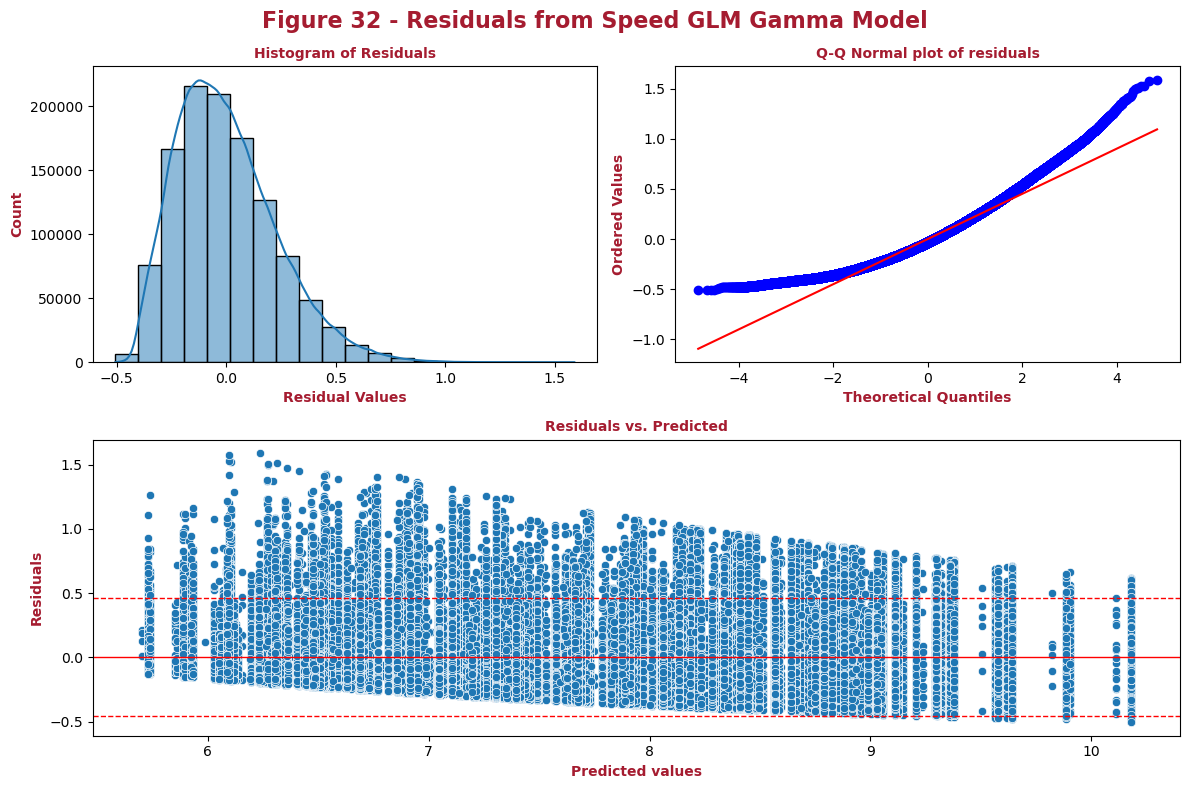

In [59]:
speed_formula = "trip_speed ~ C(start_region, Treatment(reference = 'Alameda'))\
    + C(bike_type, Treatment(reference = 'Electric'))\
    + C(user_type, Treatment(reference = 'Casual'))\
    + C(hour_block, Treatment(reference = 'Midday'))\
    + C(weekend, Treatment(reference = 0))\
    + C(holiday, Treatment(reference = 0))"
speed_glm_sample = smf.glm(speed_formula,
                           data = speed_sample_df, 
                           family = sm.families.Gamma(link = sm.families.links.Log())).fit(scale = 'X2', cov_type = 'HC1')
glm_dispersion = speed_glm_sample.pearson_chi2 / speed_glm_sample.df_resid
print("Dispersion Parameter:", format(glm_dispersion, '.3f'))
print(speed_glm_sample.summary())

plot_resid_fun({'prediction': speed_glm_sample.fittedvalues,
                'residuals': speed_glm_sample.resid_pearson,
                'title': 'Figure 32 - Residuals from Speed GLM Gamma Model',
                'figsize': (12, 8)});

## Speed Effects

<a id="speed_effects"></a>

The reference category was a non-holiday Midday weekday trip taken by a casual user on an electric bicycle that started in Alameda County, with an estimated mean speed of 8.39 mph. Relative to this baseline:

1. **Bike type**. Trips on **standard** bicycles were approximately 18% slower, which is equivalent to electric bicycles being approximately 21% faster.
2. **User type**. Trips by **members** were approximately 6% faster than those by casual users.
3. **Day of week**. **Weekend** trips were approximately 3% slower than weekday trips.
4. **Federal Holidays**. In the earlier models tested, **holiday indicator** was not statistically significant. In this final model, it reaches statistical significance, but the effect is negligible in size (−0.6% for non holidays relative to Federal Holidays). The counterintuitive pattern in **Figure 14** is therefore not supported by the model.
5. **Time of day**. **Midday** trips (12pm to 3:59pm) were slower than trips in almost every other period. **Overnight** (1am to 3:59am) and **Early Morning** (4am to 7:59pm) trips were 11% to 14% faster while **PM Peak** (4pm to 7:59pm) had a negligible effect (-0.1%). See **Figure 33**. 
6. **Region**. Trips originating in **Alameda** County were faster than those in every other region. The largest difference was in **Downtown Los Angeles**, where trips were approximately 15% slower, followed by trips in the **Westside** which were 12% slower. The trips in the other Northern California were regions slower but in the 5% to 8% range. Trips in **North Hollywood**, while 11% slower, have a wide confidence interval of 4% to 18%, as seen on **Figure 34**.

[Return to contents](#contents)

In [60]:
# Model Coefficients and Effects
glm_speed_coeff_df = model_coeff_fun(speed_glm_sample)
glm_speed_effects_df = model_coeff_fun(speed_glm_sample, log = True)
glm_speed_effects_df['color'] = ['green' if c else 'red' for c in glm_speed_effects_df['sign']]
glm_speed_effects_df['height'] = glm_speed_effects_df['effect_975'] - glm_speed_effects_df['effect_025']

# Intercept
speed_intercept = glm_speed_coeff_df[glm_speed_coeff_df['coef_name'] == 'Intercept']['coef'].iloc[0]
glm_avg_speed = np.exp(speed_intercept)
print('Average Model Speed: ' + str(format(glm_avg_speed, '.2f')) + ' mph\n')
glm_speed_effects_df

Average Model Speed: 8.39 mph



,effect_name,effect_ref,p_value,sign,effect,effect_025,effect_975,color,height
0,start_region_DTLA,Alameda,0.000,True,-0.145552,-0.147856,-0.143585,green,0.004271
1,start_region_North Hollywood,Alameda,0.003,True,-0.114852,-0.182905,-0.041130,green,0.141775
2,start_region_San Francisco,Alameda,0.000,True,-0.052947,-0.054461,-0.051620,green,0.002841
3,start_region_Santa Clara,Alameda,0.000,True,-0.086434,-0.089717,-0.083323,green,0.006394
4,start_region_Westside,Alameda,0.000,True,-0.116620,-0.119266,-0.113966,green,0.005300
5,bike_type_Standard,Electric,0.000,True,-0.177494,-0.177988,-0.176342,green,0.001646
6,user_type_Member,Casual,0.000,True,0.063962,0.062899,0.065027,green,0.002128
7,hour_block_Early Morning,Midday,0.000,True,0.139968,0.137690,0.142250,green,0.004560
8,hour_block_Late Evening,Midday,0.000,True,0.030970,0.029425,0.032518,green,0.003093
9,hour_block_Morning,Midday,0.000,True,0.050325,0.049171,0.051271,green,0.002100


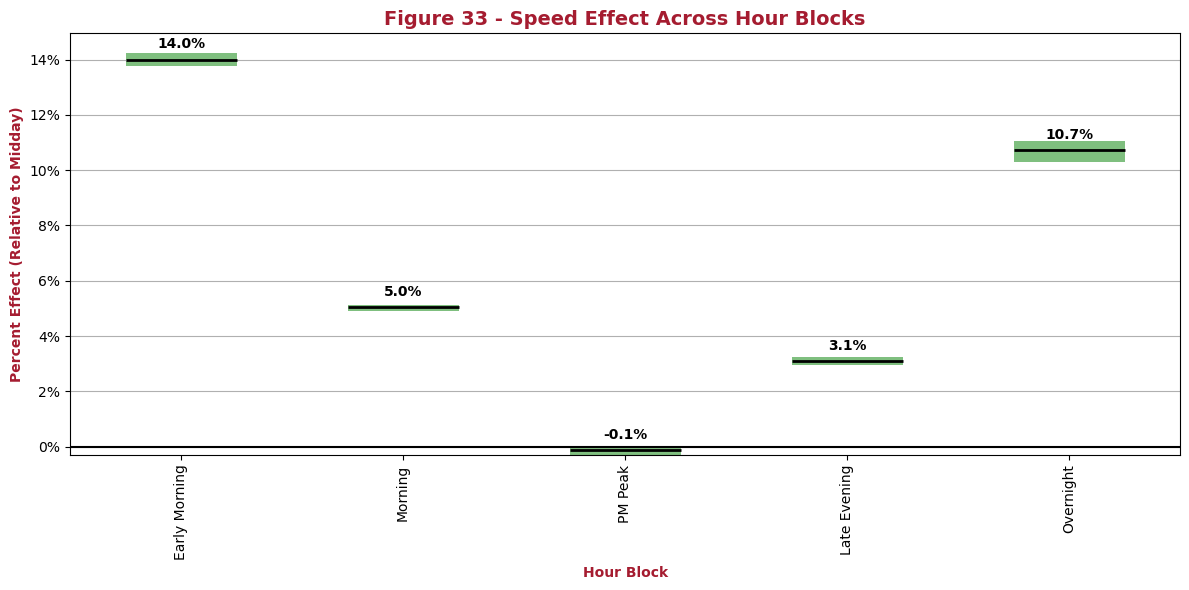

In [61]:
plot_df = glm_speed_effects_df[glm_speed_effects_df['effect_name'].str.contains('hour_block')]
plot_df['effect_name'] = plot_df['effect_name'].str.replace('hour_block_', '')
plot_df['order'] = plot_df['effect_name'].map({'Early Morning': 1,
                                               'Morning': 2,
                                               'PM Peak': 3,
                                               'Late Evening': 4,
                                               'Overnight': 5})
plot_df = plot_df.sort_values(by = 'order')

plot_effects_fun({'data': plot_df,
                  'x': 'effect_name',
                  'bar_min': 'effect_025',
                  'bar_label': 'effect',
                  'bar_height': 'height',                  
                  'y_label': 'Percent Effect (Relative to Midday)',
                  'x_label': 'Hour Block',
                  'title': 'Figure 33 - Speed Effect Across Hour Blocks',
                  'figsize': (12, 6)});

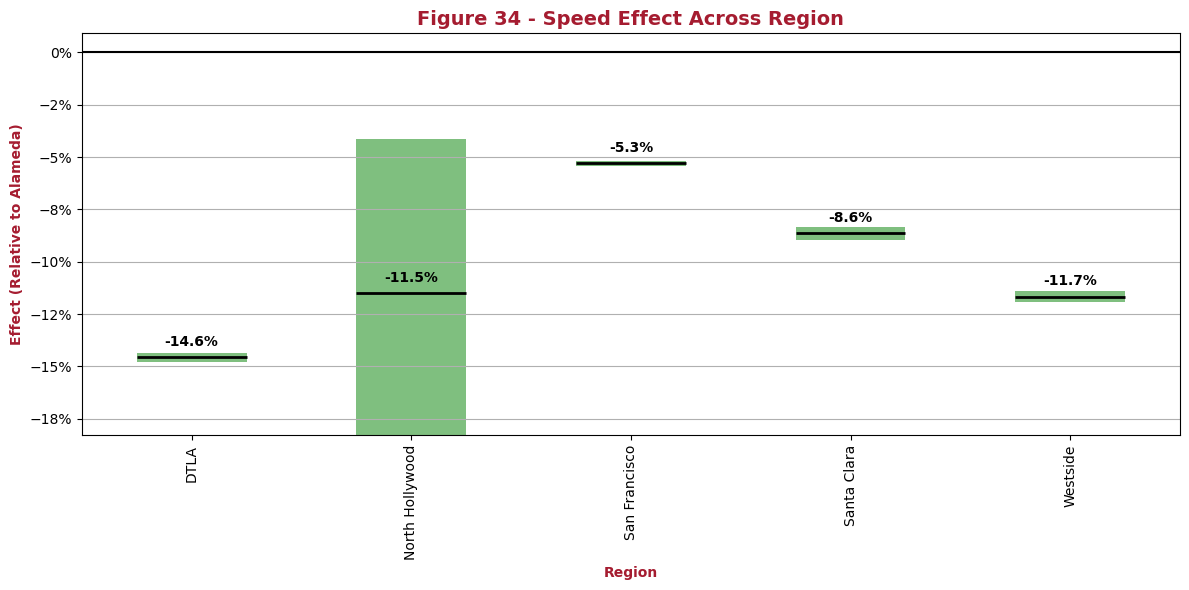

In [62]:
plot_df = glm_speed_effects_df[glm_speed_effects_df['effect_name'].str.contains('start_region')]
plot_df['effect_name'] = plot_df['effect_name'].str.replace('start_region_', '')

plot_effects_fun({'data': plot_df,
                  'x': 'effect_name',
                  'bar_min': 'effect_025',
                  'bar_label': 'effect',
                  'bar_height': 'height',                  
                  'y_label': 'Effect (Relative to Alameda)',
                  'x_label': 'Region',
                  'title': 'Figure 34 - Speed Effect Across Region',
                  'figsize': (12, 6)});

# Part 5 - MCMC Estimation of Round Trip Probability
<a id="mcmc"></a>

Owing to computational constraints, the analysis was restricted to trips originating at the most frequently used station, in each region, during the most recent month of observation (June 2026). Stations with truncated coordinates were excluded to ensure that station identity could be resolved unambiguously. The resulting analytic dataset comprised 10,149 bike trips, each annotated with **start_region**, **bike_type** (Standard or Electric), and **user_type** (Member or Casual). 

The outcome of interest was whether a trip was a round trip, that is, one that began and ended at the same station, coded as a binary indicator (1 = Round Trip, 0 = One Way).

Future refinements to the model could include tunning the number of chains to allow for building more complex hierarchical MCMC models with region as grouping factors. Partial pooling stabilizes estimates for stations with few trips by shrinking them toward the overall mean.

[Return to contents](#contents)

In [63]:
# Limit analysis to most popular station during most recent month
top_mcmc_stations_df = bike_df\
    [(bike_df['date_month'] == '2026-06-01') & (bike_df['start_station_id'] != 'Unknown')]\
    .groupby(['start_region', 'start_station_id'], as_index = False)\
    .agg(trips = ('trip', 'sum'))\
    .sort_values(by = ['start_region', 'trips'], ascending = [True, False])
top_mcmc_stations_df['station_rank'] = top_mcmc_stations_df.groupby(['start_region']).cumcount()+1
top_mcmc_stations_df = top_mcmc_stations_df[top_mcmc_stations_df['station_rank'] <= 1].reset_index(drop = True)

top_mcmc_stations_df

,start_region,start_station_id,trips,station_rank
0,Alameda,OK-F4,1253,1
1,DTLA,3005,1225,1
2,North Hollywood,4606,103,1
3,San Francisco,SF-J29,5532,1
4,Santa Clara,SJ-M7-1,1192,1
5,Westside,4214,1449,1


In [64]:
# Remove stations with truncated coordinates (less than 6 decimal points)
coord_decimals = 6

mcmc_df = bike_df\
    [(bike_df['date_month'] == '2026-06-01') & (bike_df['end_station_id'] != 'Unknown')]\
    .merge(top_mcmc_stations_df[['start_region', 'start_station_id']], on =['start_region', 'start_station_id'], how = 'inner')

for col in['start_lat', 'start_lon', 'end_lat', 'end_lon']:
    coord_filter = [len(re.sub(r'^.*?\.', '', format(coord, '.6f'))) == coord_decimals for coord in mcmc_df[col]]
    mcmc_df = mcmc_df[coord_filter].reset_index(drop = True)
mcmc_df['bikeType'] = (mcmc_df['bike_type'] == 'Standard').astype(int)
mcmc_df['userType'] = (mcmc_df['user_type'] == 'Member').astype(int)
mcmc_df['roundTrip'] = (mcmc_df['trip_route_category'] == 'Round Trip').astype(int)
mcmc_df = mcmc_df[['start_region', 'start_station_id', 
                   'bike_type', 'bikeType', 
                   'user_type', 'userType',
                   'trip_route_category', 'roundTrip']]
print('MCMC data contains ' + format(mcmc_df.shape[0], ',.0f') + ' bike trips \n')

mcmc_df.head(10)

MCMC data contains 10,149 bike trips 



,start_region,start_station_id,bike_type,bikeType,user_type,userType,trip_route_category,roundTrip
0,DTLA,3005,Electric,0,Member,1,Round Trip,1
1,DTLA,3005,Standard,1,Member,1,One Way,0
2,DTLA,3005,Electric,0,Member,1,One Way,0
3,DTLA,3005,Electric,0,Member,1,One Way,0
4,Westside,4214,Standard,1,Member,1,Round Trip,1
5,Westside,4214,Standard,1,Member,1,One Way,0
6,North Hollywood,4606,Standard,1,Member,1,One Way,0
7,North Hollywood,4606,Standard,1,Casual,0,One Way,0
8,Westside,4214,Standard,1,Casual,0,One Way,0
9,DTLA,3005,Standard,1,Member,1,One Way,0


## Roundtrip MCMC Model (Bernouilli)
<a id="mcmc_model"></a>

Round-trip behavior was modeled using Bayesian logistic regression. Let $y_i \in \{0, 1\}$ denote the **roundTrip** indicator for trip $i = 1, \dots, 10{,}149$. We assumed:

$$y_i \sim \text{Bernoulli}(p_i),$$
$$\text{logit}(p_i) = \alpha + \beta_{\text{bike}}\, bikeType_i + \beta_{\text{user}}\, userType_i + \beta_{\text{int}}\, bikeType_i\, userType_i,$$

where $bikeType_i = 1$ for Standard bikes and 0 for Electric bikes, and $userType_i = 1$ for Member users and 0 for Casual users. The intercept $\alpha$ therefore represents the log-odds of a round trip for a Casual user riding an Electric bike. The coefficient $\beta_{\text{bike}}$ is the shift in log-odds for Standard relative to Electric bikes among Casual users, and $\beta_{\text{user}}$ is the shift for Members relative to Casual users among Electric bike riders. The interaction coefficient $\beta_{\text{int}}$ captures the extent to which the effect of bike type differs between user types (equivalently, the effect of user type differs between bike types). The log-odds of a round trip for a Member riding a Standard bike is $\alpha + \beta_{\text{bike}} + \beta_{\text{user}} + \beta_{\text{int}}$. An interaction was included because exploratory cross-tabulation indicated that the association between bike type and round-trip behavior differed in direction across user types, which an additive specification cannot represent.

Prior Specification

Weakly informative priors were placed on all parameters to regularize estimation without imposing strong assumptions:

$$\alpha \sim \mathcal{N}(0, 2^2), \qquad \beta_{\text{bike}}, \beta_{\text{user}}, \beta_{\text{int}} \sim \mathcal{N}(0, 1.5^2).$$

The prior on the intercept admits baseline Round Trip probabilities spanning most of the unit interval. The priors on the slope and interaction coefficients are symmetric about zero, so they do not presuppose the direction of any effect.

[Return to contents](#contents)

In [65]:
# Convert to numpy
bikeType = mcmc_df['bikeType'].to_numpy()
userType = mcmc_df['userType'].to_numpy()
roundTrip = mcmc_df['roundTrip'].to_numpy()

# For plot consistency
mcmc_d = {'alpha': 'Intercept (Electric, Casual)',
          'beta_bike': 'Standard (Reference = Electric)',
          'beta_user': 'Member (Reference = Casual)',
          'beta_int': 'Interaction (userType * bikeType)'}
mcmc_vars = [key for key, label in mcmc_d.items()]
mcmc_labels = [label for key, label in mcmc_d.items()]

# Defining our PyMC model
mcmc_random_seed = 23
with pm.Model() as station_trial:
    # Priors for unknown model parameters
    alpha = pm.Normal(mcmc_vars[0], mu = 0, sigma = 2)
    beta_bike = pm.Normal(mcmc_vars[1], mu = 0, sigma = 1.5)
    beta_user = pm.Normal(mcmc_vars[2], mu = 0, sigma = 1.5)
    beta_int  = pm.Normal(mcmc_vars[3],  mu=0, sigma = 1.5)

     # Deterministic expected value of outcome
    logit_p = alpha + beta_bike * bikeType + beta_user * userType + beta_int * bikeType * userType

    # Likelihood (sampling distribution) of observations
    roundTripObs = pm.Bernoulli('roundTrip', logit_p = logit_p, observed = roundTrip)

station_trial

## Prior Predictive Checks
<a id="mcmc_ppc"></a>

Prior predictive simulations were conducted to evaluate whether the specified priors implied plausible data before the model was conditioned on the observed trips 

Under the weakly informative priors, the prior predictive distribution of the total number of round trips, on the left panel of **Figure 35**, was approximately uniform across the range from 0& to 100% of trips, with density declining only near the upper and lower extremes. This plateau indicates that, a priori, the model regarded nearly any overall round-trip rate between near zero and a majority of trips as comparably plausible. This is the intended behavior of a weakly informative specification: it avoids concentrating belief on a narrow range of outcomes and allows the likelihood to dominate the posterior.

The observed data, on the right panel of **Figure 35**, is heavily imbalanced. Most trips are one way trips, and round trips constitute 11% of the total trips. This lies well within the support of the prior predictive distribution, so the priors are not in conflict with the data and the model can recover the observed rate without difficulty. Because the sample is large (n = 10,149), the likelihood is expected to dominate but a more informative prior centered on a low baseline rate would be a defensible alternative.

The implied prior distributions of the model parameters on **Figure 36** were centered near zero and the 94% highest density intervals were wide and consistent with the specified Normal(0, 2²) and Normal(0, 1.5²) priors.

We are satisfied that no direction of effect was presupposed and are ready to MCMC sample the model. 

[Return to contents](#contents)

In [66]:
# Prior predictive checks
with station_trial:
    prior_checks = pm.sample_prior_predictive(draws = 50, random_seed = mcmc_random_seed)
prior_checks.keys()

Sampling: [alpha, beta_bike, beta_int, beta_user, roundTrip]


KeysView(Inference data with groups:
	> prior
	> prior_predictive
	> observed_data)

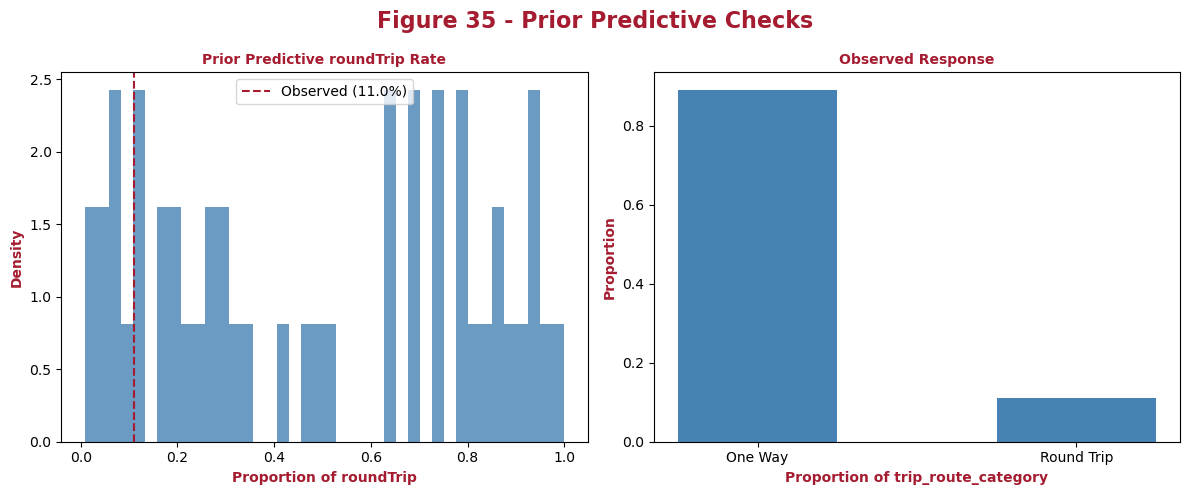

In [67]:
sim_rate = prior_checks.prior_predictive['roundTrip'].mean(dim = 'roundTrip_dim_0').values.ravel()
obs_rate = sum(mcmc_df['roundTrip']) / mcmc_df.shape[0]

fig, ax = plt.subplots(1, 2, figsize = (12, 5))
fig.suptitle('Figure 35 - Prior Predictive Checks', 
             fontsize = 16,
             fontweight = 'bold',
             color = '#A51C30')

# Prior predictive
ax[0].hist(sim_rate, bins = 40, density = True, color = 'steelblue', alpha = 0.8)
ax[0].axvline(obs_rate, color = '#A51C30', ls = '--', label = 'Observed (' + format(obs_rate, '.1%') + ')')
ax[0].set_title('Prior Predictive roundTrip Rate', fontdict = title_font_dict)
ax[0].set_xlabel('Proportion of roundTrip', fontdict = axis_font_dict)
ax[0].set_ylabel('Density', fontdict = axis_font_dict)
ax[0].legend()

# Observed outcome: bar chart, since the response is binary
props = np.bincount(roundTrip, minlength = 2) / len(roundTrip)
ax[1].bar([0, 1], props, color = 'steelblue', width = 0.5)
ax[1].set_xticks([0, 1])
ax[1].set_xticklabels(['One Way', 'Round Trip'])
ax[1].set_title('Observed Response', fontdict = title_font_dict)
ax[1].set_ylabel('Proportion', fontdict=axis_font_dict)
ax[1].set_xlabel('Proportion of trip_route_category', fontdict = axis_font_dict)

plt.tight_layout();

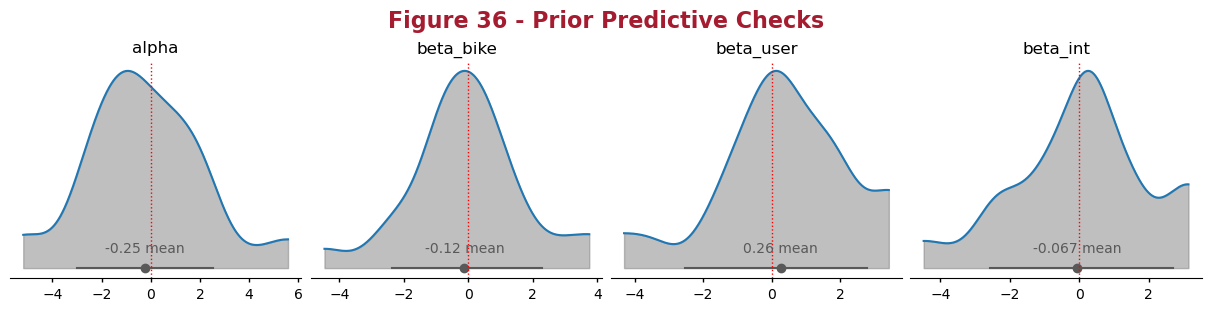

In [68]:
plot_prior_pred_fun({'prior_checks': prior_checks,
                     'var_names': mcmc_vars,
                     'title': 'Figure 36 - Prior Predictive Checks',
                     'figsize': (12, 3)});

## MCMC Posterior Distribution
<a id="mcmc_posterior"></a>

Posterior distributions were approximated by Markov chain Monte Carlo using the No-U-Turn Sampler (NUTS), an adaptive variant of Hamiltonian Monte Carlo. Two independent chains were run, each with 1,000 tuning iterations followed by 1,000 posterior draws, and the default target acceptance rate was set to 0.80. Convergence was assessed using the potential scale reduction factor ($\hat{R}$), bulk and tail effective sample sizes, trace plots, and the count of divergent transitions. 

The trace plots in **Figure 37** show well-mixed, stationary chains that fluctuate around a stable mean with no visible trends or drifts, and the posterior densities of the two chains overlapped closely for all four coefficients, indicating convergence.

**Figure 38** shows that the 94% highest density intervals across the two chains for all coefficients excluded zero. The posterior distributions in **Figure 39** is consitent and all coefficients are well separated from zero. 

[Return to contents](#contents)

In [69]:
with station_trial:
    idata = pm.sample(return_inferencedata = True, 
                      chains = 2,
                      random_seed = mcmc_random_seed)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [alpha, beta_bike, beta_user, beta_int]


Output()

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 6624 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


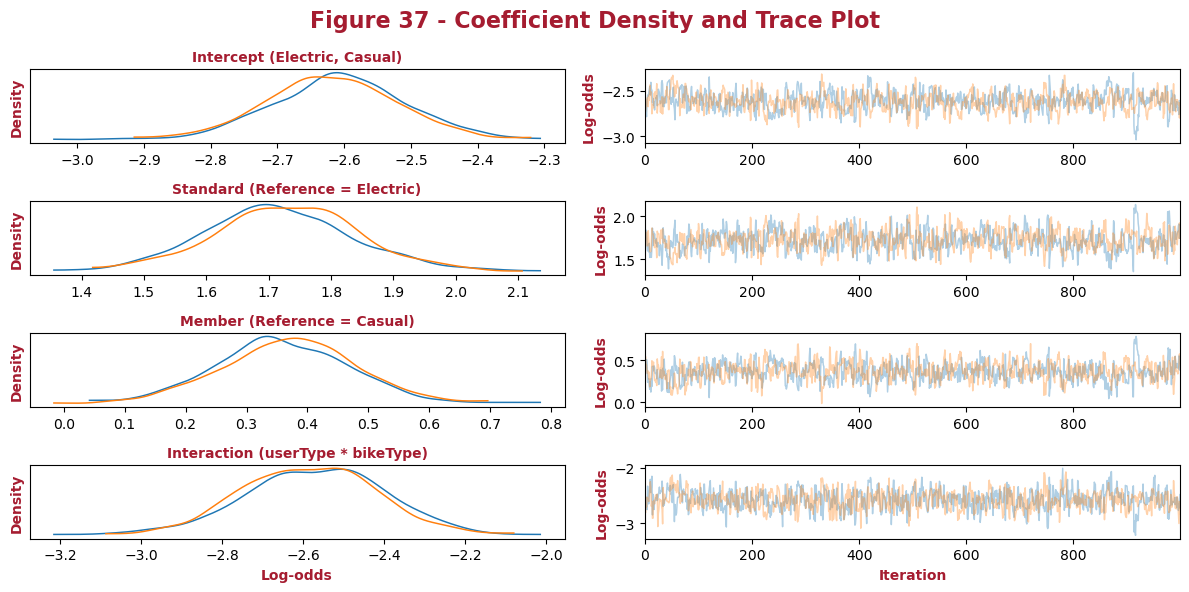

In [70]:
plot_trace_fun({'idata': idata,
                'var_names': mcmc_vars,
                'labels': mcmc_d,
                'title': 'Figure 37 - Coefficient Density and Trace Plot',
                'figsize': (12, 6)});

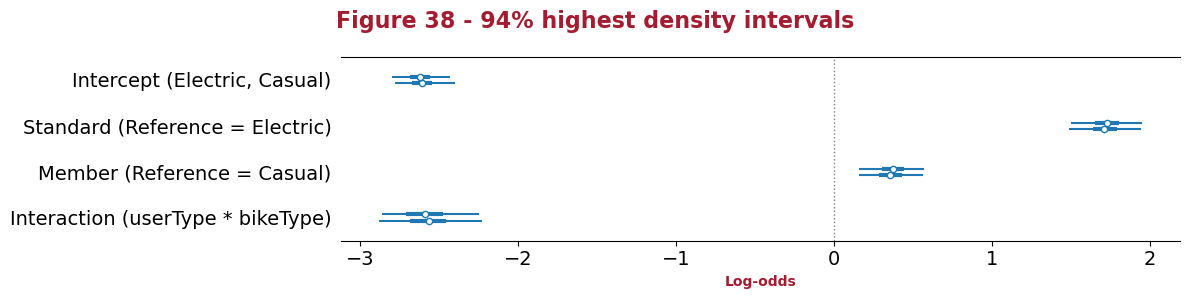

In [71]:
plot_hdi_fun({'idata': idata,
              'hdi_prob': 0.94,
              'var_names': mcmc_vars,
              'labels': mcmc_labels,
              'title': 'Figure 38',
              'figsize': (12, 3)});

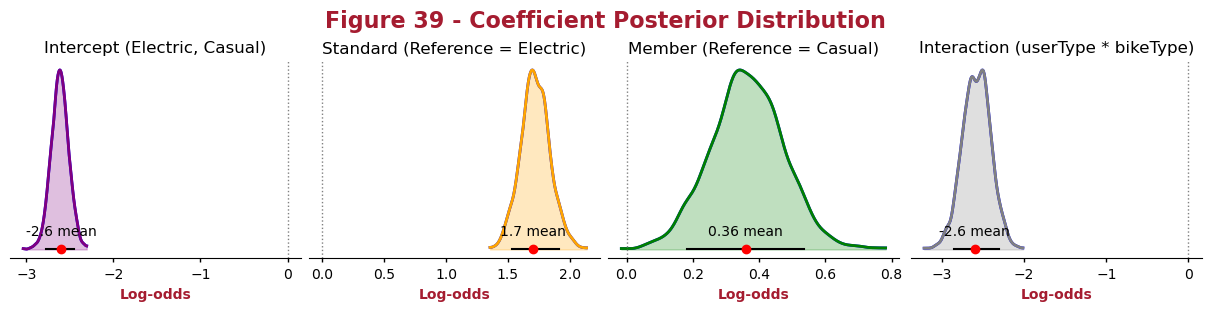

In [72]:
plot_post_dist_fun({'idata': idata,
                    'var_names': mcmc_vars,
                    'titles': mcmc_labels,
                    'colors': ['purple', 'orange', 'green', 'grey'],
                    'title': 'Figure 39 - Coefficient Posterior Distribution',
                    'figsize': (12, 3)});

## MCMC Sampling
<a id="mcmc_sampling"></a>

Posterior estimates were precise, and convergence diagnostics were satisfactory. For all parameters:
1. $\hat{R}$ = 1.00
2. Bulk and tail effective sample sizes ≥ 525
3. Monte Carlo standard errors ≤ 0.004).

The Monte Carlo standard errors in **Figure 40** are small across all quantiles and were highest in the tails, as expected. The local and quantile effective sample sizes stayed well above the recommended minimum of 400 for every parameter, indicating that the posterior mean, central intervals and tail quantiles were all estimated reliably.

[Return to contents](#contents)

In [73]:
mcmc_summary = az.summary(idata, var_names = mcmc_vars, hdi_prob = 0.94)
mcmc_summary[['mcse_mean', 'mcse_sd', 'ess_bulk', 'ess_tail', 'r_hat']]

,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,0.004,0.003,525.0,635.0,1.0
beta_bike,0.005,0.004,532.0,845.0,1.0
beta_user,0.005,0.004,556.0,747.0,1.0
beta_int,0.006,0.004,696.0,859.0,1.0


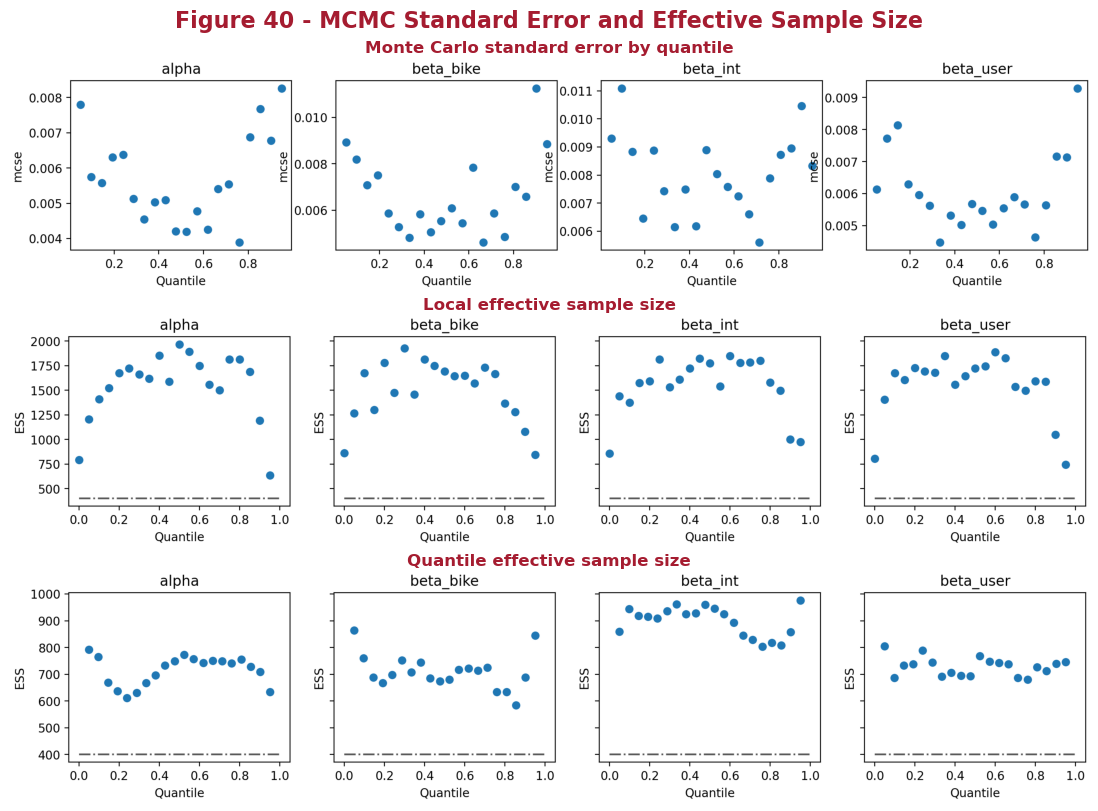

In [74]:
plot_mcse_ess_fun({'idata': idata,
                    'title': 'Figure 40 - MCMC Standard Error and Effective Sample Size',
                    'figsize': (12, 8)});

## Inference from the Posterior Predictive (MCMC)
<a id="mcmc_inference"></a>

The baseline log-odds of −2.61 corresponds to a Round Trip probability of about 6.8% for Casual users on Electric bikes.

Among Casual users, Standard bikes had much higher odds of a round trip than Electric bikes (β = 1.72, odds ratio ≈ 5.6, 94% HDI: 1.50 to 1.95 on the log-odds scale). Among Members, the association reversed (combined effect ≈ −0.86). 

Members on Electric bikes had modestly higher odds than Casual users (β = 0.36, odds ratio ≈ 1.4), but on Standard bikes Members had far lower odds (combined effect ≈ −2.22).

The calibration plot built with the PAVA (pool-adjacent-violators algorithm) method in **Figure 41** tracks the diagonal and stays within the posterior predictive band across the full range of predicted probabilities, which indicates that the interaction model was well calibrated. 

The posterior predictive distribution in **Figure 42** is centered at approximately 11%.

[Return to contents](#contents)

In [75]:
mcmc_summary[['mean', 'sd', 'hdi_3%', 'hdi_97%']]

,mean,sd,hdi_3%,hdi_97%
alpha,-2.614,0.100,-2.803,-2.428
beta_bike,1.722,0.118,1.498,1.949
beta_user,0.364,0.110,0.158,0.563
beta_int,-2.579,0.171,-2.864,-2.232


In [76]:
with station_trial:
    pm.sample_posterior_predictive(idata, extend_inferencedata = True, random_seed = mcmc_random_seed)

Sampling: [roundTrip]


Output()

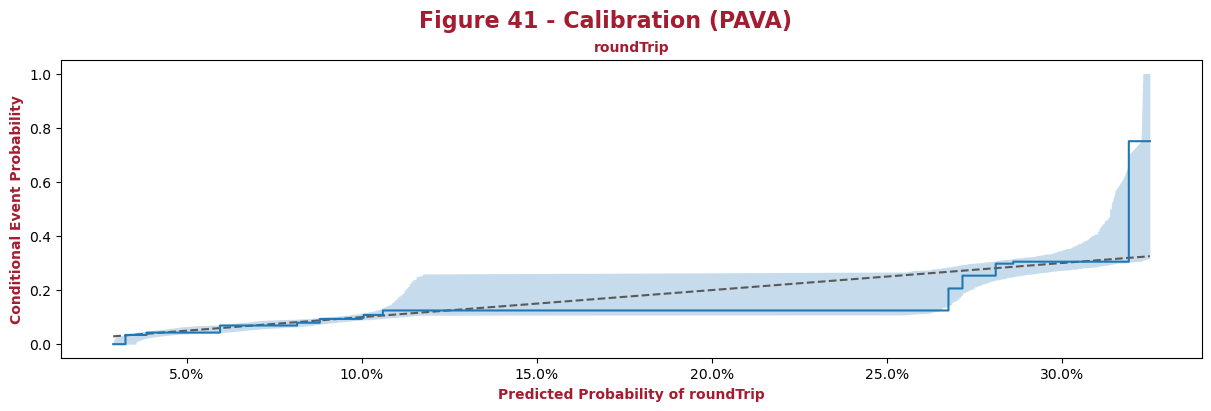

In [77]:
plot_ppc_pava_fun({'idata': idata,
                   'response': 'roundTrip',
                    'title': 'Figure 41 - Calibration (PAVA)',
                    'figsize': (12, 4)});

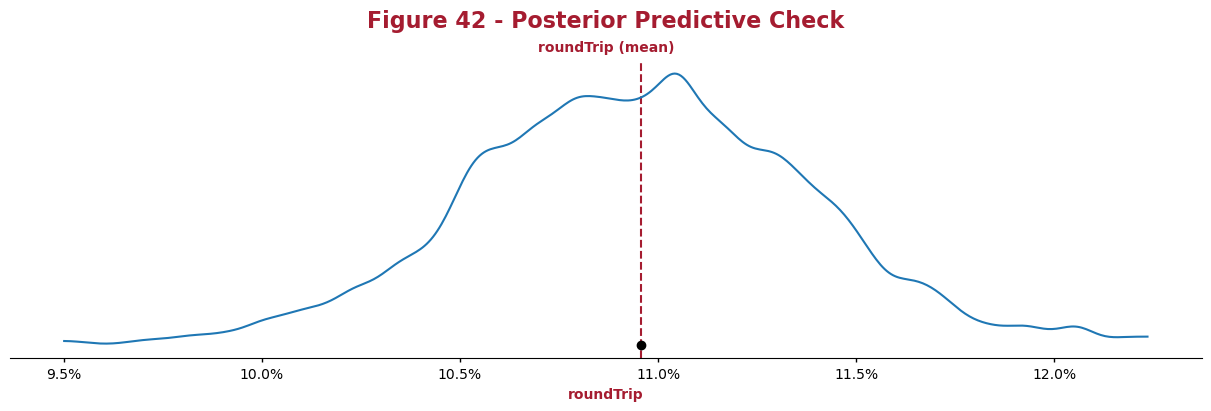

In [78]:
plot_posterior_pred_fun({'idata': idata,
                         'response': 'roundTrip',
                         'title': 'Figure 42 - Posterior Predictive Check',
                         'figsize': (12, 4)});

In [79]:
# Posterior Coefficients
alpha_posterior = idata.posterior['alpha'].to_numpy().ravel()
beta_bike_posterior = idata.posterior['beta_bike'].to_numpy().ravel()
beta_user_posterior = idata.posterior['beta_user'].to_numpy().ravel()
beta_int_posterior = idata.posterior['beta_int'].to_numpy().ravel()

# Calculate Posterior Probability
inv_logit = lambda x: 1 / (1 + np.exp(-x))
prob_d = {'Electric / Casual': inv_logit(alpha_posterior),
          'Electric / Member': inv_logit(alpha_posterior + beta_user_posterior),
          'Standard / Casual': inv_logit(alpha_posterior + beta_bike_posterior),
          'Standard / Member': inv_logit(alpha_posterior + beta_bike_posterior + beta_user_posterior + beta_int_posterior)}

print('Predicted Round Trip Probability:')
for key, value in prob_d.items():
    print('  ' + key + ': ' + post_ci_fun(value, 0.94, '.2%'))

# Observed Round Trip Rate
obs_rt_rate_df = mcmc_df\
    .groupby(['bike_type', 'user_type', 'trip_route_category'], as_index = False)\
    .agg(trips = ('start_region', 'count'))\
    .pivot(index = ['bike_type', 'user_type'],
           columns = 'trip_route_category', 
           values = 'trips')\
    .reset_index()
obs_rt_rate_df['Trips'] = (obs_rt_rate_df['Round Trip'] + obs_rt_rate_df['One Way']) 
obs_rt_rate_df['Round_Trip_Pct'] = obs_rt_rate_df['Round Trip'] / obs_rt_rate_df['Trips']
obs_rt_rate_df['Round_Trip_Pct'] = [format(p, '.2%') for p in obs_rt_rate_df['Round_Trip_Pct']]

print('\n Observed Round Trip Rates:')
obs_rt_rate_df

Predicted Round Trip Probability:
  Electric / Casual: 6.85% (94% CI: 5.72% to 8.11%)
  Electric / Member: 9.54% (94% CI: 8.81% to 10.33%)
  Standard / Casual: 29.08% (94% CI: 26.85% to 31.31%)
  Standard / Member: 4.30% (94% CI: 3.46% to 5.20%)

 Observed Round Trip Rates:


trip_route_category,bike_type,user_type,One Way,Round Trip,Trips,Round_Trip_Pct
0,Electric,Casual,1500,107,1607,6.66%
1,Electric,Member,4623,490,5113,9.58%
2,Standard,Casual,1050,433,1483,29.20%
3,Standard,Member,1864,82,1946,4.21%


In [80]:
alpha_post = idata.posterior['alpha'].to_numpy().ravel()
beta_bike_post = idata.posterior['beta_bike'].to_numpy().ravel()
beta_user_post = idata.posterior['beta_user'].to_numpy().ravel()
beta_int_post = idata.posterior['beta_int'].to_numpy().ravel()

contrasts = [('Standard vs Electric | Casual users', beta_bike_post),
             ('Standard vs Electric | Member users', beta_bike_post + beta_int_post),
             ('Member vs Casual | Electric bikes',   beta_user_post),
             ('Member vs Casual | Standard bikes',   beta_user_post + beta_int_post),
             ('Interaction (ratio of odds ratios)',  beta_int_post)]

for label, b in contrasts:
    orr = np.exp(b)
    print(label)
    print('  Odds ratio: ' + format(orr.mean(), '.2f') + ' (94% CI: ' + 
          format(np.percentile(orr, 3), '.2f') + ' to ' + format(np.percentile(orr, 97), '.2f') + ')')
    print('  P(OR > 1): ' + format((b > 0).mean(), '.1%') + '\n')

Standard vs Electric | Casual users
  Odds ratio: 5.63 (94% CI: 4.48 to 7.05)
  P(OR > 1): 100.0%

Standard vs Electric | Member users
  Odds ratio: 0.43 (94% CI: 0.34 to 0.52)
  P(OR > 1): 0.0%

Member vs Casual | Electric bikes
  Odds ratio: 1.45 (94% CI: 1.17 to 1.77)
  P(OR > 1): 100.0%

Member vs Casual | Standard bikes
  Odds ratio: 0.11 (94% CI: 0.09 to 0.14)
  P(OR > 1): 0.0%

Interaction (ratio of odds ratios)
  Odds ratio: 0.08 (94% CI: 0.05 to 0.10)
  P(OR > 1): 0.0%



# Part 6 - Bayesian Estimation of Station Paired Rates by Region
<a id="station_to_station"></a>

For each of the six California regions, we identified the most frequently traveled station pair and used conjugate Bayesian inference to estimate the probability that a bicycle checked out at the origin station of that pair is returned to its paired destination station. For brevity, we refer to this event as a **paired** rate or probability.

The most popular station pairs are:
| Station | Start Station | End Staion | Distance (Miles) |
| :--- | :---: | ---: | ---: |
| Alameda | North Side of Lake Merritt | 19th Street BART station| 0.44 |
| DTLA | South End of City Hall | Union Station| 0.49 |
| North Hollywood | North Hollywood High School | North Hollywood Metro station| 0.60 |
| San Francisco | Levi’s Plaza near Pier 19 | Ferry Building in Embarcadero| 0.84 |
| Santa Clara | San José State University (Northwest corner) | San José State University (Southeast corner)| 0.48 |
| Westside |Venice Ocean Front Walk | Santa Monica Metro station| 1.41 |

[Return to contents](#contents)

In [81]:
popular_routes_df = pd.DataFrame()
for r in sorted(set(bike_df['start_region'])):
    popular_routes_df = pd.concat([popular_routes_df, station_to_station_fun(bike_df, r, top_n = 1)], axis = 0).reset_index(drop = True)

station_to_station_plot_fun(popular_routes_df, num_cols = 3, num_rows = 2, w = 1200, h = 400, z = 13)

Top 6 Station-to-Station Routes in Alameda, DTLA, North Hollywood, San Francisco, Santa Clara, Westside



In [82]:
# Paired if bike returned to most popular station pair
popular_routes_df = popular_routes_df\
    [['cal_region', 'start_region', 'start_station_id', 'end_station_id']]\
    .rename(columns = {'end_station_id': 'paired_station_id'})

paired_df = bike_df\
    .merge(popular_routes_df, on = ['cal_region', 'start_region', 'start_station_id'], how = 'inner')
paired_df.loc[paired_df['end_station_id'] == paired_df['paired_station_id'], 'paired_route'] = 1
paired_df['paired_route'] = paired_df['paired_route'].fillna(0).astype(int)
paired_df = paired_df[['bike_year', 'date', 'date_month', 'cal_region', 'start_region', 'start_station_id',
                       'end_station_id', 'paired_station_id', 'paired_route']]

paired_df.head(5)

,bike_year,date,date_month,cal_region,start_region,start_station_id,end_station_id,paired_station_id,paired_route
0,2022,2021-07-01,2021-07-01,SoCal,Westside,4214,4214,4215,0
1,2022,2021-07-01,2021-07-01,SoCal,Westside,4214,4536,4215,0
2,2022,2021-07-01,2021-07-01,SoCal,Westside,4214,4215,4215,1
3,2022,2021-07-01,2021-07-01,SoCal,Westside,4214,4215,4215,1
4,2022,2021-07-01,2021-07-01,SoCal,Westside,4214,4214,4215,0


## Beta-Bernoulli Conjugate Model
<a id="conjugate_model"></a>

We specified an uninformative Beta prior, $\text{Beta}(\alpha, \beta)$, for the station **paired** probability. As seen in **Figure XX**, the probability of the parameter $\theta$ is uniform between 0 and 1. 

Because the Beta distribution is conjugate to the Bernoulli likelihood, the posterior is also Beta-distributed: $\text{Beta}(\alpha + s,\ \beta + f)$, where $s$ and $f$ denote the observed numbers of successes and failures, respectively. We will estimate a separate posterior for each **bike year** in order to characterize how the probability of a station success has changed over time.

[Return to contents](#contents)

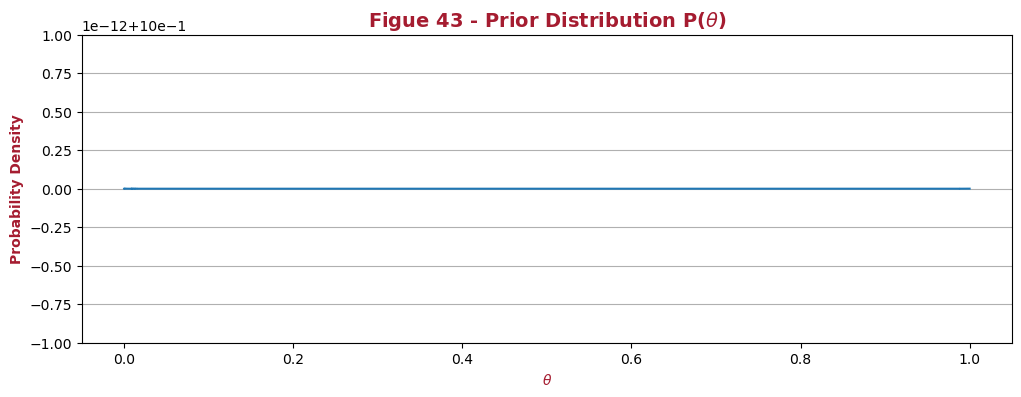

In [83]:
prior_a = 1
prior_b = 1
thetas = np.linspace(0, 1, 5000)

# Plot PDF
y = ss.beta.pdf(thetas, prior_a, prior_b)
fig, ax = plt.subplots(figsize = (12, 4))
plt.plot(thetas, y)
plt.title('Figue 43 - Prior Distribution P(' + r'$\theta$' + ')' , fontdict = title_large_font_dict)
plt.xlabel(r'$\theta$', fontdict = axis_font_dict)
plt.ylabel('Probability Density', fontdict = axis_font_dict)
plt.grid(axis = 'y')
plt.show()

## Inference from the Posterior Distribution (Beta)
<a id="conjugate_posterior"></a>

**Figure 44** thru **Figure 49** illustrate the sequential evolution of the posterior distributions across geographic **regions** for each of the five **bike years** within the dataset. At the onset of each annual cycle, the model is initialized with identical, weakly informative priors. As empirical observations accrue throughout the course of the year, these priors are iteratively updated via Bayesian inference, converging upon the final year-end posterior estimates.

1. **Figure 44: Alameda**. In 2026, the posterior paired probability reached **22.3%**. This metric reflects a sustained downward trajectory over the preceding three-year period, declining from 30.8% in 2024.
2. **Figure 45: DTLA**. In 2026, the paired probability rose to **40.2%**. This figure represents a substantial upward shift compared to the prior two-year period, during which the proportion plateaued at 25.3%.
3. **Figure 46: North Hollywood**. In 2026, the paired probability was estimated at **53.7%**. Notably, this region has demonstrated persistent stability, maintaining a proportion above 40.0% across each of the preceding four years.
4. **Figure 47: San Francisco**. In 2026, the paired probability stood at **8.6%**, marking a return to levels comparable to those observed in 2022. Following an interim peak of 14.5% in 2024, the proportion steadily contracted to its current baseline.
5. **Figure 48: Santa Clara**. In 2026, the paired probability reached **12.8%**. This outcome extends a consistent multi-year upward trend, with the proportion increasing each of the last three years.
6. **Figure 49: Westside**. In 2026, the paired probability fell to **25.6%**. This value represents the lowest estimated proportion recorded for the region within the five-year observation window.

[Return to contents](#contents)

In [84]:
# Calculate Posterior Hyperparameters
paired_posterior_df = paired_df\
    .groupby(['cal_region', 'start_region', 'bike_year'], as_index = False)\
    .agg(success = ('paired_route', 'sum'),
         trips = ('cal_region', 'count'))\
    .sort_values(by = ['start_region', 'bike_year'], ascending = [True, True])
paired_posterior_df['failure'] = paired_posterior_df['trips'] - paired_posterior_df['success']
paired_posterior_df['posterior_mean'] = (prior_a + paired_posterior_df['success']) / (prior_b + paired_posterior_df['trips'])
paired_posterior_df['color'] = paired_posterior_df['bike_year'].map({2022: '#FFDEAD',
                                                                     2023: '#F4A460',
                                                                     2024: '#808080',
                                                                     2025: '#000000',
                                                                     2026: '#000080'})
paired_posterior_df.drop(['color'], axis = 1).head(5)

,cal_region,start_region,bike_year,success,trips,failure,posterior_mean
0,NorCal,Alameda,2022,189,1967,1778,0.096545
1,NorCal,Alameda,2023,790,3220,2430,0.245576
2,NorCal,Alameda,2024,1160,3765,2605,0.308285
3,NorCal,Alameda,2025,1379,5145,3766,0.268169
4,NorCal,Alameda,2026,1470,6604,5134,0.222710


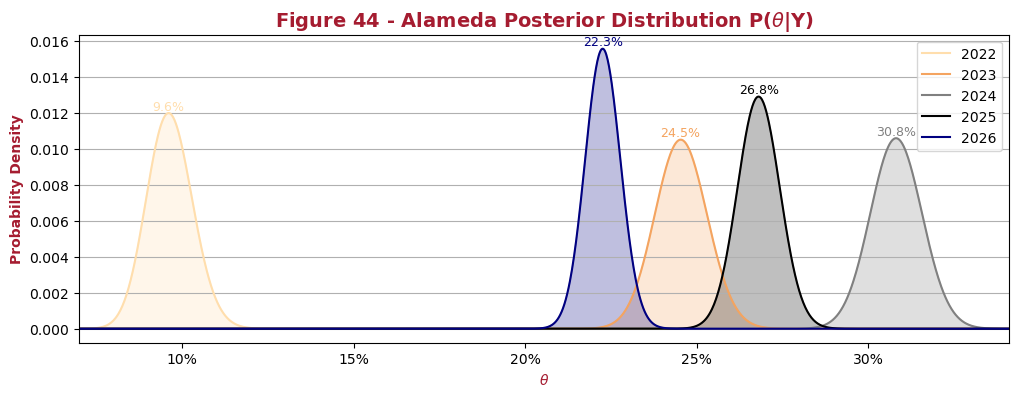

In [85]:
station_post_dist_fun({'data': paired_posterior_df[paired_posterior_df['start_region'] == 'Alameda'],
                       'thetas': thetas,
                       'prior_a': prior_a,
                       'prior_b': prior_b,
                       'title': 'Figure 44 - Alameda Posterior Distribution P(' + r'$\theta$' + '|Y)',
                       'figsize': (12, 4)});

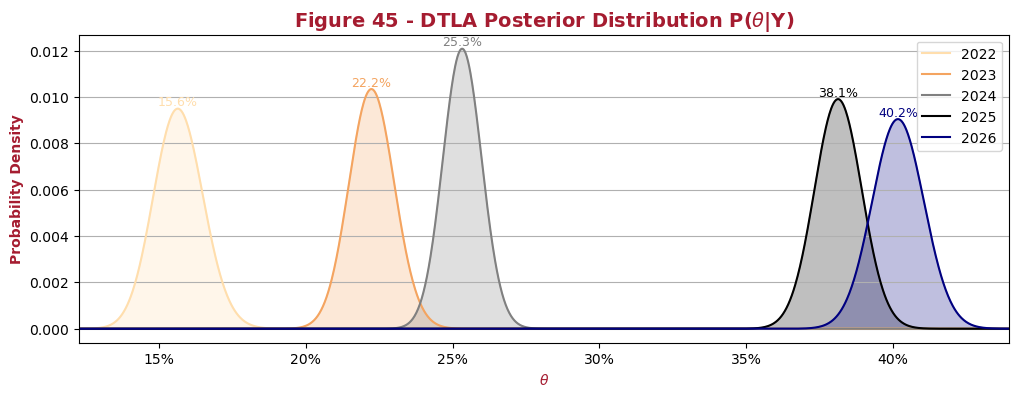

In [86]:
station_post_dist_fun({'data': paired_posterior_df[paired_posterior_df['start_region'] == 'DTLA'],
                       'thetas': thetas,
                       'prior_a': prior_a,
                       'prior_b': prior_b,
                       'title': 'Figure 45 - DTLA Posterior Distribution P(' + r'$\theta$' + '|Y)',
                       'figsize': (12, 4)});

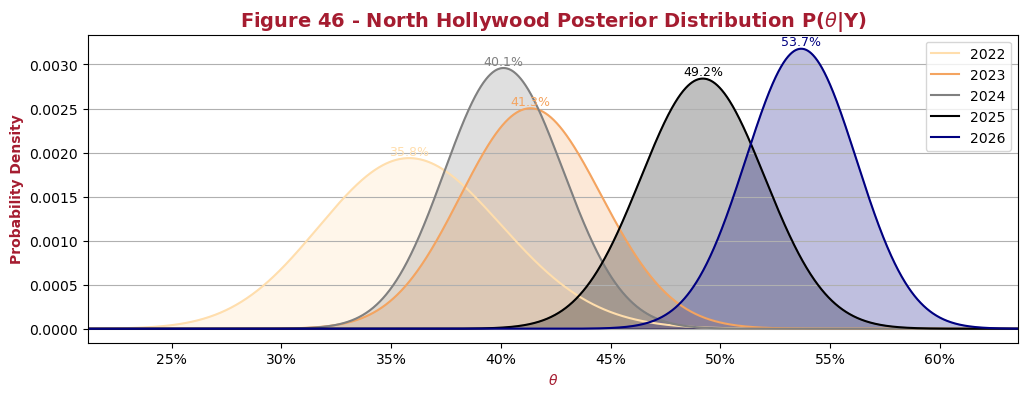

In [87]:
station_post_dist_fun({'data': paired_posterior_df[paired_posterior_df['start_region'] == 'North Hollywood'],
                       'thetas': thetas,
                       'prior_a': prior_a,
                       'prior_b': prior_b,
                       'title': 'Figure 46 - North Hollywood Posterior Distribution P(' + r'$\theta$' + '|Y)',
                       'figsize': (12, 4)});

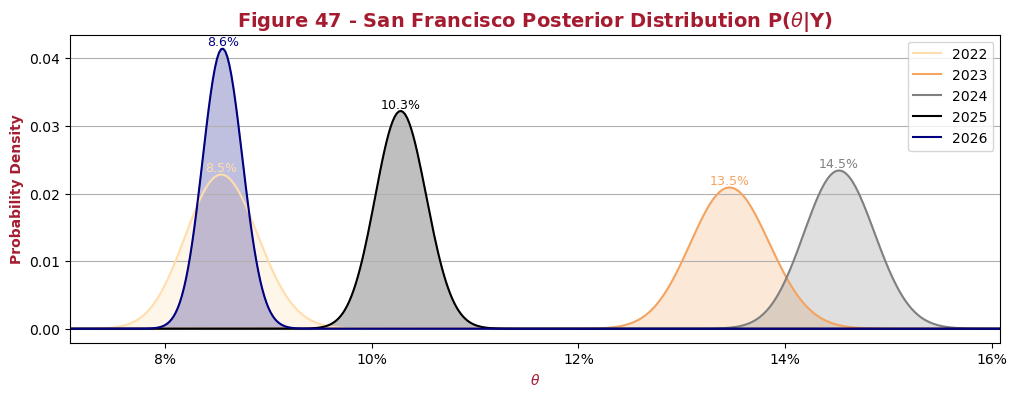

In [88]:
station_post_dist_fun({'data': paired_posterior_df[paired_posterior_df['start_region'] == 'San Francisco'],
                       'thetas': thetas,
                       'prior_a': prior_a,
                       'prior_b': prior_b,
                       'title': 'Figure 47 - San Francisco Posterior Distribution P(' + r'$\theta$' + '|Y)',
                       'figsize': (12, 4)});

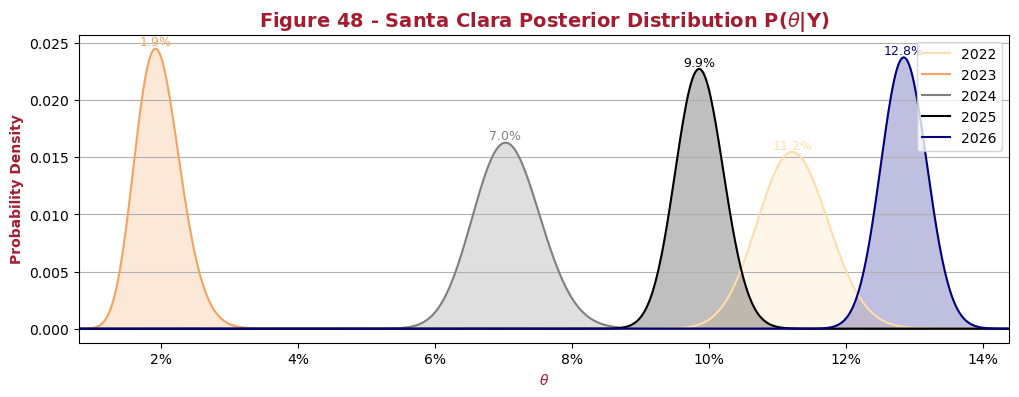

In [89]:
station_post_dist_fun({'data': paired_posterior_df[paired_posterior_df['start_region'] == 'Santa Clara'],
                       'thetas': thetas,
                       'prior_a': prior_a,
                       'prior_b': prior_b,
                       'title': 'Figure 48 - Santa Clara Posterior Distribution P(' + r'$\theta$' + '|Y)',
                       'figsize': (12, 4)});

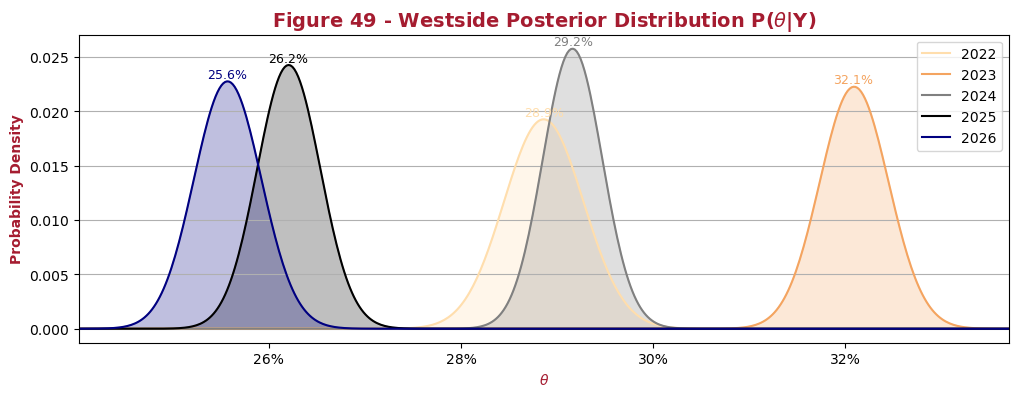

In [90]:
station_post_dist_fun({'data': paired_posterior_df[paired_posterior_df['start_region'] == 'Westside'],
                       'thetas': thetas,
                       'prior_a': prior_a,
                       'prior_b': prior_b,
                       'title': 'Figure 49 - Westside Posterior Distribution P(' + r'$\theta$' + '|Y)',
                       'figsize': (12, 4)});

# Conclusions:
<a id="conclusions"></a>

### Summary:
This analysis used six complementary statistical approaches to understand California bike-share demand, trip behavior, and station-level patterns. Negative Binomial GLMs handled overdispersed ridership counts, and nonparametric bootstrapping tested a regional hypothesis. OLS on log-transformed outcomes modeled trip duration and distance, a Gamma GLM modeled trip speed, and two Bayesian methods covered round-trip behavior (MCMC logistic regression with prior predictive checks and calibration) and station-pair return rates (conjugate Beta-Bernoulli updating). Using several modeling frameworks let each outcome be matched to a distribution that fit its structure, and the diagnostics showed where each model was adequate and where it fell short.

### Key takeaways:
1. **Ridership is growing quickly**. By 2026, ridership was roughly double the 2022 baseline, with demand peaking in the PM commute block and bottoming out overnight.
2. **The July dip is not a San Francisco story**. We hypothesized that SF’s foggy summers drove the decline, but the bootstrap showed that nearly every region fell from June to July, and North Hollywood fell the most (39%) while San Francisco fell 19%. The decline is statewide, though without weather data we cannot identify its cause.
3. **Special events drive the outliers**. CicLAvia street closures, New Year’s night, and Día de los Muertos accounted for many of the most influential observations. Labeling local events in the data would likely improve future models.
4. **Who rides, and on what, shapes how they ride**. Members take shorter, faster trips that stay closer to their origin, while casual riders and holiday riders go longer and farther. Electric bikes are about 21% faster than standard bikes.
5. **Round trips depend on the combination of bike and rider type**. Casual users on standard bikes had about 5.6 times the odds of a round trip compared with casual users on electric bikes, while for members the pattern reversed. Overall, round trips were only about 11% of trips.
6. **Popular station pairs behave very differently by region**. The 2026 posterior probability of a rider returning a bike to the paired station ranged from 8.6% in San Francisco to 53.7% in North Hollywood, and it has been trending in different directions across regions.

### Limitations and next steps:
The duration, distance, and speed models explain only 7% to 18% of the variation, so they describe group-level patterns rather than predicting individual trips. Trip purpose, route choice, and weather were not observed. Adding weather data, an event calendar, and individually labeled holidays would be the most promising refinements.

[Return to contents](#contents)

# References:
<a id="ref"></a>

**LA County Bikeway Projects:** https://pw.lacounty.gov/tpp/bike/index.cfm?action=projects&CFID=73153822&CFTOKEN=6d74aa096542fc89-E8F5981C-BBE2-885E-EA394C55251D9130<br/>
**Southern California Data:** https://bikeshare.metro.net/about/data/<br/>
**Northern California Data:** https://lyftbikes.com/system-data<br/>
**San Francisco Fog:** https://en.wikipedia.org/wiki/San_Francisco_fog<br/>
**8 Things Mark Twain Didn't Really Say**: https://www.mentalfloss.com/literature/authors/10-things-mark-twain-didnt-really-say<br/>
**North Hollywood CicLAvia:** https://ciclavia.org/events/ciclamini-noho-2023-09/<br/>
**Venice CicLAvia:** https://ciclavia.org/events/venice-blvd-2024-04/<br/>
**Dia de los Muertos**: https://en.wikipedia.org/wiki/Day_of_the_Dead<br/>
**15 Facts about Latino well-being in California**: https://latino.ucla.edu/research/15-facts-latinos-california/<br/>
**Dia de los Muertos Bike Rides**: https://www.sjbikeparty.org/2026/1162523543010409/<br/>
**Average Walking Speed by Age and Sex:** https://www.healthline.com/health/exercise-fitness/average-walking-speed#average-speed-by-sex<br/>

[Return to contents](#contents)